# 03 · Steering com a feature 19219 do SAE v3 — fact-checking no AVeriTeC

**Dissertação de mestrado (PPGCC/PUCRS).** Estágio 2 da RQ2: *existe uma feature responsável
pela abstenção que possa ser manipulada para reduzir a abstenção sem depender de mais
evidência?* Aqui **manipulamos a feature 19219** (identificada no `02-sae-v3.ipynb`) durante o
veredito e medimos o efeito com as **mesmas métricas do Seminário de Andamento** (SA).

> Modelo: **Llama-3.1-8B-Instruct** (4-bit nf4), camada 15, SAE `v3_llama`.
> **Estado:** em execução. As seções 1–4 descrevem o desenho; a seção 5 lê os resultados que
> já existem (reexecutar o notebook atualiza).
>
> 👉 **Resposta direta — melhorou ou piorou?** Ver **§5.0**: uma tabela única comparando
> Single-step, Iterative e cada combinação de steering, com o veredito de cada uma.


## 1. Pergunta e hipóteses

O SA (§6.2) propõe dois testes com a feature, em dois cenários de evidência:
- **diminuir** a feature — o modelo passa a decidir (abstém menos) sem ganhar evidência nova?
- **aumentar** a feature — o modelo passa a abster mesmo quando decidiria?

**Hipóteses registradas antes de ver os resultados:**
- **H1 (causal):** aumentar a feature 19219 aumenta a taxa de NEI; diminuí-la reduz — nas
  três condições de evidência.
- **H2 (especificidade):** o mesmo steering com **features aleatórias** do SAE, de mesmo
  tamanho, **não** produz o mesmo efeito na taxa de NEI.
- **H3 (aplicação):** como o modelo **super-abstém** (prevê NEI em ~40% dos claims; o gold tem
  7%), diminuir a feature com evidência **aumenta a acurácia** sem piorar muito o erro das
  predições decididas.
- **H4 (sem evidência — hipótese do Lucas):** sem evidência, o modelo **não abstém sempre**:
  tenta decidir com o **conhecimento interno** (paramétrico). Se isso for verdade, a abstenção
  sem evidência é bem menor que 100% já no α = 0.


## 2. Desenho experimental

### 2.1 Condições de evidência (3, não 4)

Na hora do veredito, Single-step e Iterative **só diferem pela evidência** que cada pipeline
recuperou. Sem evidência, o prompt é o mesmo nos dois — então "sem evidência" é **uma**
condição só:

| condição | o que o modelo vê no prompt de veredito |
|---|---|
| **sem evidência** (`none`) | claim + data + autor; blocos de evidência e de Q&A **vazios** |
| **Single-step** (`single`) | a evidência e os Q&A que o pipeline **Single-step HF** recuperou |
| **Iterative** (`iterative`) | a evidência e os Q&A que o pipeline **Iterative HF** recuperou |

Para cada condição: **α = 0** (sem manipulação, o baseline), α < 0 (**diminuir** a feature) e
α > 0 (**aumentar**).

### 2.2 Como a feature é manipulada

Somamos ao *residual stream* da camada 15, em todas as posições, um "empurrão" na direção da
feature — **exatamente a Eq. 4 de Ferrando et al. (2025)**, com a mesma notação:

$$x \leftarrow x + \alpha \cdot d_{19219}$$

> **De onde vem a fórmula.** Ferrando et al. (2025), *"Do I Know This Entity? Knowledge Awareness
> and Hallucinations in Language Models"* (ICLR 2025), Eq. 4: $x_{new} \leftarrow x + \alpha\, d_j$ —
> *"increasing/decreasing the activation value of an SAE latent, a_j(x), is equivalent to doing
> activation steering (Turner et al., 2023) with the decoder latent vector"*. Somar um vetor ao
> residual stream para guiar o modelo é o *activation addition* de **Turner et al. (2023,
> ActAdd)**; somar numa camada só, em todas as posições, segue **Arditi et al. (2024, Eq. 3)**:
> $x^{(l)} \leftarrow x^{(l)} + r^{(l)}$. A única diferença é o índice: o $d_j$ deles é o nosso
> $d_{19219}$ (a feature $j$ = 19219).

**Símbolo por símbolo:**

| símbolo | o que é | tipo | valor |
|---|---|---|---|
| $x$ | o **residual stream** na camada 15, num token — a representação interna do modelo naquele ponto | vetor de 4.096 números | muda a cada token |
| $\alpha$ | o **coeficiente de steering** — o "botão de volume": quanto e em que sentido empurrar (**não é bias**). Mesmo α de Ferrando et al. (2025) | um número | α < 0 diminui a feature; α > 0 aumenta; α = 0 = sem steering |
| $d_{19219}$ | a **direção da feature 19219**: a linha dela no **decoder** do SAE, normalizada para comprimento 1 | vetor de 4.096 números | fixo |
| $\leftarrow$ | "**substitui** $x$ por…" | — | — |
| $R$ *(para interpretar α)* | o **tamanho típico de $x$**: norma média do residual stream na posição da decisão (camada 15, nas 598.930 decisões do harvest) | um número | **8,375** |
| $\alpha/R$ *(para interpretar α)* | α em **múltiplos do tamanho do resíduo** | um número | grade de −2 a +2 |

**O que a fórmula faz, em 2 passos:**
1. **Monta o empurrão** $\alpha \cdot d_{19219}$: um número multiplicando um vetor de comprimento 1.
   O resultado é um vetor que **aponta na direção da feature** (ou na oposta, se α < 0) e tem
   **comprimento |α|**.
2. **Soma o empurrão ao residual stream** e o modelo continua o processamento a partir do $x$
   modificado. A única operação sobre $x$ é essa **soma**.

**Como ler o tamanho de α — α/R.** O valor absoluto de α depende da escala do resíduo de cada
modelo. Por isso reportamos também **α/R**: o α em múltiplos do tamanho típico do resíduo — como
Ferrando et al. (2025, nota 5) descrevem o α que escolheram: *"corresponds to around two times the
norm of the residual stream"* (ou seja, α/R ≈ 2). A grade é definida em α/R e convertida em α
por α = (α/R) × 8,375.

**Exemplo com α/R = −0,25 (α = −2,09):** o empurrão tem comprimento 2,09. Como o $x$ tem tamanho
típico de 8,4, deslocamos o $x$ em **~25% do tamanho dele**, no sentido **contrário** à feature de
abstenção — e a abstenção cai. Com α/R = +0,25 (α = +2,09), mesmo tamanho, no sentido **da**
feature — e a abstenção sobe. α/R = 1 (α = 8,375) empurra 100% do tamanho do resíduo.

**Por que reportar α/R e não só α:** α/R é interpretável ("quanto do tamanho do resíduo") e
comparável entre modelos — o resíduo do Qwen3 é ~10× maior que o do Llama, então o mesmo α teria
efeitos muito diferentes.

**Onde acontece:** na **saída da camada 15**, em **todos os tokens** (os do prompt e cada token
gerado). No código (`fcsae/steering/factcheck_sae.py`): `vec = α · d` (com α = β·R, onde `β` é o
nome interno de α/R nos arquivos de resultado) e, num *hook* da camada, `saída + vec`.

**Nota técnica:** o SAE v3 opera no espaço normalizado da entrada (média 0, norma 1; ver
`02-sae-v3.ipynb`), mas a direção $d_{19219}$ é aplicada ao resíduo **bruto** — a escala certa vem
de α, que é medido na escala do resíduo bruto (via R).

**Por quê (literatura):**
- **Manipular uma feature = somar a direção dela no decoder.** Ferrando et al. (2025, Eq. 4):
  *"increasing/decreasing the activation value of an SAE latent, a_j(x), is equivalent to
  doing activation steering (Turner et al., 2023) with the decoder latent vector, i.e.
  updating the residual stream as follows: x_new ← x + α·d_j"*. Eles usam exatamente isso para
  **induzir e suprimir a recusa por desconhecimento de entidades** — fenômeno próximo do nosso
  (a 19219 ativa em claims sobre entidades obscuras e trivialidades, ver `02-sae-v3.ipynb`).
- **Coeficiente relativo à norma do resíduo.** Ferrando et al. (2025, nota 5): o coeficiente
  escolhido *"corresponds to around two times the norm of the residual stream"*. Reportar α também
  como múltiplo de R (α/R) torna a escala interpretável e comparável entre modelos.
- **Uma camada, todas as posições.** Arditi et al. (2024, Eq. 3): *"for activation addition,
  we intervene only at layer l, and across all token positions"*.

### 2.3 Grade de α e como o α reportado é escolhido

**Grade planejada:** α/R ∈ {−2, −1,5, −1, −0,75, −0,5, −0,25, 0, 0,25, 0,5, 0,75, 1, 1,5, 2}.
**Grade executada:** α/R ∈ {−1, −0,75, −0,5, −0,25, 0, 0,25, 0,5, 0,75, 1} — ou seja,
α ∈ {−8,38, −6,28, −4,19, −2,09, 0, +2,09, +4,19, +6,28, +8,38} —, nas três condições e nos 500
claims → **curva dose-resposta**.

**Por que a grade foi cortada em |α/R| ≤ 1 (decisão de 28/09/2026, com os dados sem evidência):**
em |α/R| = 1 o modelo **já degenera** — com α/R = +1, 91% das respostas entram em *loop*
(*"I have no information about this claim. I have no evidence…"* repetido) até o limite de 1.536
tokens; com α/R = −1, 30%. Doses maiores só degenerariam mais, nenhum critério de qualidade as
escolheria, e cada célula levaria ~7 h. É o mesmo procedimento do CAA (Panickssery et al., 2024):
explorar, observar a degradação do texto e **limitar a faixa** do multiplicador.

**Por quê reportar a curva (e não um ponto só):** o efeito do steering depende da dose e varia
muito entre exemplos — Tan et al. (2024) mostram que *"steerability is highly variable across
different inputs"*. E multiplicadores grandes **degradam o texto**: Panickssery et al. (2024)
— o método **CAA** (*Contrastive Activation Addition*), que soma às ativações a diferença média
entre exemplos com e sem um comportamento, multiplicada por um fator — *"find that steering with larger multipliers results in a degradation in the quality of
the open-ended text … Therefore, we choose to limit the multiplier range to strike a balance
between effectively steering the model's behavior and maintaining the overall quality"*.

**Escolha do α para as tabelas — sem ajustar no conjunto de teste.** Dividimos o AVeriTeC dev
em duas metades fixas: **validação** = `claim_id` par (250) e **teste** = `claim_id` ímpar (250).
- **Critério (sem usar rótulos):** em cada condição e em cada sentido (diminuir / aumentar),
  o **maior |α| cujas respostas continuam coerentes** em ≥ 80% dos claims **da validação**
  ("coerente" = a resposta contém um dos 4 rótulos, escrito como rótulo (maiúsculas), **ou** uma recusa por falta de informação
  escrita por extenso — ver §2.3.1). Não usar a acurácia evita escolher o α que "dá o melhor
  resultado" no próprio conjunto avaliado.
- **Reporte:** as métricas desse α na metade de **teste**, contra o α = 0 na mesma metade.
- **Referência:** selecionar o vetor/coeficiente num conjunto de **validação** é o protocolo de
  Arditi et al. (2024, §2.3: *"by evaluating each candidate vector over validation sets"*) e de
  Ferrando et al. (2025, nota 5: *"We use a validation set to select an appropriate steering
  coefficient α"*).
- **Escolha nossa (sem referência direta):** o limiar de 80%. É uma operacionalização do
  "limite de qualidade" do CAA; a curva completa permite ver o efeito de outros limiares.

#### 2.3.1 Correção do critério de qualidade (27/09/2026, depois das primeiras células)

**O que mudou.** O critério original era *"a resposta contém um dos 4 rótulos"* (**com
rótulo**). Na célula *sem evidência, α/R = +0,25* (feature **aumentada**), 26% das respostas não
tinham rótulo — mas **não eram o modelo quebrando**: eram **abstenções escritas por extenso**,
p.ex. *"I'm unable to find any information about the claim…"* (79 casos), *"Unfortunately, I
don't have any evidence to review… The task requires evidence…"*. É justamente o comportamento
que a manipulação deveria induzir. Com o critério original, o sentido "aumentar" seria
penalizado por produzir o que queremos medir.

**Novo critério (coerente)** = contém um dos 4 rótulos escrito como rótulo (MAIÚSCULAS, por extenso) **ou** uma **recusa por falta de
informação** detectada por correspondência de frases — o mesmo procedimento de Ferrando et al.
(2025, §5): *"we define a set of common knowledge refusal completions and detect if any of these
occur with string matching, e.g. 'Unfortunately, I don't have access to real-time
information…'"*. Uma recusa de **segurança** (*"I cannot provide information or guidance on
illegal or harmful activities"*) **não** conta: Ferrando et al. separam a recusa por
conhecimento da recusa *"due to safety concerns"*.

**Salvaguardas contra escolha conveniente:**
1. a lista de frases (`REFUSAL_PATTERNS` em `fcsae/steering/factcheck_sae.py`) foi definida a
   partir das duas primeiras células sem evidência e **congelada** para todas as células;
2. reportamos **os dois critérios** lado a lado (coerente e com rótulo) e qual α cada um escolhe;
3. na regra de rótulo do pipeline essas respostas já viravam NEI, então as métricas (acurácia,
   F1, NEI) **não mudam** — muda só qual α é considerado "sem quebrar o modelo".

#### 2.3.2 Três regras de escolha do α, lado a lado (29/09/2026, com a grade completa)

**Por que revisitar.** Com a grade completa, a regra da §2.3 (maior |α| com ≥ 80% de respostas
coerentes) escolhe **α/R = −1** do lado "diminuir" nas três condições — justamente a dose em que o
modelo **degrada**: diz SUPPORTED para quase tudo e ~20% das respostas entram em *loop* até o limite
de 1.536 tokens. Isso acontece porque, em geral, o modelo escreve o rótulo **antes** de entrar em
loop, e o critério "coerente" só verifica se há rótulo (ou recusa). A conclusão do §5.0 passa a
**depender da regra**, então reportamos **as três** (decisão do Lucas, 29/09/2026: *"no nb03 eu quero
ver tudo"*):

| regra | escolhe, na **validação** (`claim_id` par)… | o que prioriza |
|---|---|---|
| **A** (a da §2.3) | o maior \|α\| com ≥ 80% de respostas **coerentes** | o **maior efeito** ainda com rótulo |
| **B** | o maior \|α\| com ≥ 80% de respostas coerentes **e sem loop** | o maior efeito **sem degeneração** |
| **C** | entre as doses que passam na B, a de **maior acurácia** | o **melhor desempenho** sem degeneração |

- **Loop** = a resposta chega ao limite de geração (≥ 1.530 dos 1.536 tokens, contados com o
  tokenizador do modelo) — o modelo não termina a resposta. É a degradação do texto que o CAA usa
  para limitar o multiplicador (Panickssery et al., 2024).
- **C** é a escolha padrão de hiperparâmetro: otimiza a métrica-alvo **na validação** e reporta no
  **teste**, que continua intocado. É também o protocolo de Ferrando et al. (2025, nota 5: *"We use a
  validation set to select an appropriate steering coefficient α"*) e de Arditi et al. (2024, §2.3:
  *"by evaluating each candidate vector over validation sets"*).
- **A** e **B** respondem melhor à pergunta **causal** ("quanto a feature controla a abstenção?"); **C**
  responde à pergunta **prática** ("manipular a feature melhora o fact-checking?"). As curvas
  completas (§5.1) cobrem todas as doses, independentemente da regra.
- A regra que vai para a dissertação ainda **não foi escolhida**; a §5.3 mostra, para cada dose, os
  números de validação que cada regra usa.

### 2.4 Controle com features aleatórias

**Status (29/09/2026): adiado** — decisão do Lucas: *"No final eu vejo se vale a pena ou não
fazermos"*. O desenho abaixo fica registrado para quando (e se) for rodado.

Nos dois α escolhidos (diminuir e aumentar), repetimos o steering trocando $d_{19219}$ pela
direção de **10 features aleatórias do mesmo SAE** (mesmo α, mesma camada), nas três condições,
em **100 claims da metade de teste**.

**Por quê:** separa o efeito **da feature** do efeito de **qualquer perturbação** de mesmo
tamanho no resíduo. É o controle de Ferrando et al. (2025): *"the average refusal rate after
steering with 10 differents random latents, using the same configuration (layer and steering
coefficient)"* (e *"a random baseline where we apply a randomly sampled SAE latent with the
same coefficient"*), aplicado num conjunto de 100 perguntas. Turner et al. (2023, Apêndice G)
fazem o análogo com vetores aleatórios *"with similar magnitudes to the steering vectors"*.

**Como as 10 features são escolhidas.** Sorteio uniforme entre as 32.767 features do dicionário diferentes
da 19219 (`numpy.random.default_rng(seed=0)`, em `fcsae/steering/factcheck_sae.py::directions`), o que as
torna reproduzíveis: **27865, 26649, 20867, 16744, 8838, 1342, 541, 10085, 5742, 2465**. Não se sorteia do
"top-k" porque o top-k é por token (as 32 features ativas em cada posição), não um conjunto fixo; o que o
controle precisa é **outra direção do mesmo dicionário**, com o mesmo tamanho (linha do decoder normalizada ×
o mesmo α). Nenhuma das 10 está entre as 15 features mais ligadas à abstenção (por Cohen's d ou cosseno com a
direção de abstenção), e o SAE tem só 2 features mortas — então o controle não "compete" com a 19219 por acaso.

### 2.5 Métricas (as do SA)

- **Rótulo de cada resposta:** o **1º rótulo que o modelo escreve** (métrica principal; §3.1) e,
  ao lado, o da regra do pipeline original;
- **Acurácia** (4 rótulos) e **macro-F1** do SA = média de F1(SUP), F1(REF), F1(NEI);
- **F1 por classe**, incluindo a **CONF**;
- **taxa de NEI** (SA, Tabela 3);
- **erro condicionado a não-NEI** (SA, Tabela 4). O próprio SA §6.2 define o critério:
  *"We consider the feature to genuinely cause this behavior if the error rate does not worsen
  more than it already does under iteration for that specific model."* No HF, a iteração piora
  esse erro do Llama em **+0,004** (0,304 → 0,308; `01-single-vs-iterative-it.ipynb`, Tabela 4);
- **coerência** (fração de respostas com rótulo ou recusa por falta de informação, §2.3.1) e
  **com rótulo** (critério original) — controle de qualidade do steering.


## 3. Fidelidade ao pipeline (o baseline)

Para que "α = 0" seja o veredito do pipeline, reconstruímos **exatamente** o que o pipeline HF
fazia no passo de veredito (`shared/modules/verdict/llm_verdict.py` e `shared/llm/hf_llm.py`
do código original):

| item | como está no experimento | verificação |
|---|---|---|
| prompt de veredito | `LLMVerdict.build_prompt`, com a evidência final e os Q&A de cada passo, lidos do `averitec_dev.jsonl` | **idêntico byte a byte** ao do código original em 1.000/1.000 prompts |
| *system prompt* | o do `HFLLM` | idêntico |
| geração | chat template, `enable_thinking=False`, *greedy*, até **1.536** tokens | = `HF_MAX_NEW_TOKENS` do pipeline |
| rótulo | `LLMVerdict.normalize`: "REFUTE"/"FALSE" em qualquer ponto → REF; depois SUPPORT, CONFLICT, NOT ENOUGH; **sem rótulo → NEI** | cópia fiel — **mas tem um defeito** (§3.1); a métrica principal usa o 1º rótulo |

**Duas diferenças registradas:**
1. **Sem evidência, o pipeline não chamava o LLM** — devolvia NEI direto (`if not evidence:
   verdict = NEI`). Na nossa condição `none`, **o modelo é chamado**, com o mesmo template e os
   blocos de evidência e Q&A vazios. É o que permite testar a H4: o "≈100% de NEI sem
   evidência" que aparecia antes era esse atalho do código, não o comportamento do modelo.
2. **A rodada do pipeline foi feita em outro ambiente** (03/09/2026). Mesmo com prompt idêntico,
   pequenas diferenças numéricas do 4-bit podem mudar vereditos limítrofes. Por isso o
   **baseline dos experimentos é o nosso α = 0** (mesmo ambiente do steering), e reportamos a
   concordância dele com as predições do pipeline.

**Um tropeço (corrigido):** a primeira rodada usava só 64 tokens de geração. Isso **cortava** o
raciocínio do modelo antes do rótulo (sem evidência, o Llama costuma começar com *"To determine
the final verdict of the claim, I'll analyze…"*) e, como a normalização do pipeline lê o texto
inteiro, explicava a maior parte das divergências com o pipeline: com 64 tokens a concordância
era de 94,8% (single) e 94,6% (iterative); com 1.536 tokens, 22 dos 26 claims divergentes do
single passaram a concordar. Todas as células usam 1.536 tokens; as de 64 foram arquivadas.


### 3.1 Um defeito na regra de rótulo do pipeline (achado em 28/09/2026)

**O que é.** A regra que o pipeline original usa para extrair o rótulo da resposta
(`LLMVerdict.normalize`) procura as palavras **nesta ordem**: primeiro "REFUTE" ou "FALSE" **em
qualquer ponto do texto**; só depois "SUPPORT", "CONFLICT" e "NOT ENOUGH". Mas a explicação típica
de uma abstenção é:

> *"**NOT ENOUGH EVIDENCE**\n\nThe evidence provided does not contain any direct evidence to
> support or **refute** the claim…"*

A expressão *"support or refute"* contém "refute" → a resposta é registrada como **REFUTED**,
embora o modelo tenha dito NOT ENOUGH EVIDENCE.

**Onde está o código e qual versão cada rodada usou (verificado em 28/09/2026).** O código do pipeline
**não está** no projeto atual (`old_method/` guarda só as saídas). Ele existe (i) na cópia antiga do
projeto em `/mnt/d/Projetos WSL/mestrado/`, que ainda tem o histórico Git, e (ii) no repositório público
`github.com/lucasfrag/iterative-question-generation`. Cada rodada gravou o commit do código no
`config.json`:

| rodadas | commit | arquivo | `normalize` |
|---|---|---|---|
| HF (este notebook) | `dc19749` (03/09/2026) | `iterative-question-generation/modules/verdict/llm_verdict.py`, linhas 85–104 | a regra descrita acima (arquivo **idêntico** ao lido) |
| Ollama (SA / ENIAC) | `53829d5` e `809230a` | `modules/verdict/llm_verdict.py` (repositório público), linhas 85–104 | **a mesma regra** |

Nos três commits, `pipeline/pipeline_factory.py` usa `LLMVerdict` no Single-step (linha 48) e no
Iterative (linha 82). Ou seja: **os números do SA e do artigo do ENIAC também foram extraídos com essa
regra**. O que não dá para medir é o **tamanho** do efeito no Ollama, porque aqueles JSONL não guardam o
texto das respostas (e o formato das respostas do Ollama pode ser diferente do HF).

**Tamanho (baseline Single-step, sem steering, 500 claims):** 76 respostas que começam com "NOT
ENOUGH EVIDENCE" são contadas como REF (74 pelo "refute" de *"support or refute"*, 2 por
"false"); em 45 delas o gold é REF, então o erro de leitura **vira acerto**. Resultado:

| baseline Single-step | regra do pipeline | 1º rótulo que o modelo escreve |
|---|---|---|
| acurácia | 0,434 | **0,360** |
| taxa de NEI | 0,422 | **0,620** |

**Por que isso também afeta o steering:** o steering muda o **tamanho da explicação**. Mais texto →
mais chance de aparecer "refute" → a regra do pipeline mistura o efeito do steering com um erro de
leitura. Foi o que fez "aumentar NEI" parecer não aumentar a abstenção com evidência.

**Exemplos e contagens de cada tipo de resposta: §4.2.**

**Decisão (28/09/2026):** a **métrica principal** deste notebook usa o **rótulo que o modelo
produziu**, ignorando a explicação (`first_label` em `fcsae/steering/factcheck_sae.py`). **Substituída em 15/10/2026 pela
regra v2 (`verdict_label`, §3.1.2).**

**O que conta como rótulo:** a expressão completa **escrita como rótulo, em MAIÚSCULAS** —
`SUPPORTED`, `REFUTED`, `NOT ENOUGH EVIDENCE`, `CONFLICTING EVIDENCE`. Verificamos nas células que o
modelo sempre escreve o veredito assim; as ocorrências em minúsculas são ele **falando** dos rótulos
(*"I cannot assess whether the claim is supported, refuted, or…"*), e palavras soltas como *"support or
refute"* não são veredito. (Uma 1ª versão desta leitura procurava as palavras sem diferenciar
maiúsculas e transformava *"no evidence to support or refute"* em SUP — corrigido ao ver os exemplos
da §4.2.)

**A leitura, em 3 passos:**
1. se a resposta **começa com um rótulo**, usa esse rótulo e ignora o resto — é o caso de quase todas
   as respostas **com evidência** (98–100% por célula; 81% em α/R = +0,5);
2. se **não começa** (sem evidência o modelo às vezes raciocina antes: *"To determine the final
   verdict… the claim is REFUTED"*), usa o **primeiro rótulo que aparece** no texto — **fora de
   enumerações das opções** (§3.1.1);
3. se **não há rótulo nenhum** (p.ex. as recusas por extenso *"I'm unable to find any information…"*),
   conta como **NEI** — o mesmo padrão do pipeline, e semanticamente correto (são abstenções).

Quando a resposta começa com um rótulo, os passos 1 e 2 dão sempre o mesmo resultado (verificado:
100% de concordância em todas as células). As métricas com a **regra do
pipeline** aparecem ao lado, para comparação com o `01-single-vs-iterative-it.ipynb`. Como todas as
células guardam o texto completo das respostas, **nada precisou ser re-rodado**.

**Consequência para a RQ1:** os números dos pipelines no notebook 01 foram calculados com essa
regra — ver a seção sobre o defeito no `01-single-vs-iterative-it.ipynb`.


#### 3.1.1 Segunda correção da leitura: enumerações das opções (28/09/2026)

**O que era.** Ao inspecionar os exemplos no SAE viewer, apareceu uma resposta lida como **SUP** que é,
na verdade, uma **recusa**:

> *"To determine the final verdict of the claim, I need more information about the evidence.
> Unfortunately, the provided evidence is empty. […] Without the evidence, I cannot accurately determine
> whether the claim is **SUPPORTED, REFUTED, NOT ENOUGH EVIDENCE, or CONFLICTING EVIDENCE/CHERRYPICKING**."*

O modelo não dá veredito: ele **cita as opções** do formato de resposta. Como a leitura do passo 2 pega
o **primeiro** rótulo em maiúsculas, pegava o "SUPPORTED" da lista.

**Correção.** Uma sequência de **dois ou mais rótulos seguidos**, separados só por vírgula, *"or"*,
*"and"* ou *"/"*, é tratada como **enumeração das opções** e ignorada (`_ENUM_RE` em
`fcsae/steering/factcheck_sae.py`); o rótulo é o primeiro que sobra, e se não sobra nenhum a resposta é
NEI (passo 3). A mesma exclusão vale para o critério "coerente" (§2.3.1), que exige um rótulo **ou** uma
recusa por falta de informação.

**Tamanho (tabela da §4.1.1):** atinge **no máximo 8 de 500 respostas** numa célula (1,6%; sem evidência,
α/R = +0,25), quase só nas **doses positivas**, onde o modelo recusa por extenso e lista as opções. As
células que sustentam os resultados (baselines α = 0 e Single α/R −0,5 / −0,75) mudam **0 ou 1** resposta;
nenhuma conclusão muda. A coerência muda em no máximo 2 respostas, longe do limite de 80%.

**Por que é o mesmo tipo de erro da §3.1:** nos dois casos a regra lia um rótulo que o modelo **mencionou**
em vez do que ele **decidiu**. Como a leitura é feita sobre o texto salvo, a correção **não exigiu re-rodar**
nenhuma célula.


#### 3.1.2 Regra de rótulo v2 (15/10/2026) — erro de grafia, abstenção por extenso e "sem rótulo"

Nas doses extremas de steering (sobretudo no Gemma3) apareceram respostas que a regra anterior lia errado: o rótulo
com **erro de grafia** (`NOT ENUFF EVIDENCE`, `**CONFLECTING EVIDENCE/CHERRYPICKing**`) e **texto sem veredito**
(`,`, `***\n***`), ambos contados como NEI pelo padrão "sem rótulo → NEI". **Decisão do Lucas:** regra v2
(`verdict_label` em `fcsae/steering/factcheck_sae.py`):

1. 1º rótulo em MAIÚSCULAS, tolerando erro de grafia, fora de enumerações das opções;
2. senão, rótulo na 1ª linha em qualquer caixa (`Supported. The claim…`);
3. senão, **abstenção por extenso** (lista `REFUSAL_PATTERNS` + "not enough / insufficient evidence") → **NEI**, como
   a *knowledge refusal* de Ferrando et al. (2025);
4. senão → **NOLABEL**: categoria própria (erro na acurácia; não conta como NEI).

**Impacto:** steering — Llama 3,2% das respostas mudam (342 NEI → NOLABEL; 86 NEI → um rótulo real), Qwen3 0,5%,
Gemma3 27% (doses ±4,5 e ±6); bases do RQ1 — só o DeepSeek muda (10 de 1.000 respostas). As bases do Llama (0,360 de
acurácia e 0,620 de NEI no Single; 0,420 e 0,494 no Iterative) não mudam. A métrica principal deste notebook passa a
ser a regra v2.

## 4. Carregamento e métricas

In [1]:
import json, glob, os, re, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

D = "../results/v3_llama/steer_sae"
CLS = ["SUP", "REF", "NEI", "CONF"]
COND = {"none": "sem evidência", "single": "Single-step", "iterative": "Iterative"}
THR = 0.80                                  # coerência mínima (§2.3)
from fcsae.steering.factcheck_sae import coherent, readable as has_label, first_label, verdict_label, REFUSAL_PATTERNS
from transformers import AutoTokenizer
_tok = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")   # conta tokens p/ detectar loop (§2.3.2)

def f1(pred, gold, c):
    tp = sum(p == c and g == c for p, g in zip(pred, gold)); fp = sum(p == c and g != c for p, g in zip(pred, gold))
    fn = sum(p != c and g == c for p, g in zip(pred, gold))
    pr = tp / (tp + fp) if tp + fp else 0.0; rc = tp / (tp + fn) if tp + fn else 0.0
    return 2 * pr * rc / (pr + rc) if pr + rc else 0.0

def metrics(pred, gold, readable):
    F = {c: f1(pred, gold, c) for c in CLS}
    nn = [(p, g) for p, g in zip(pred, gold) if p != "NEI"]
    return {"n": len(pred), "acc": np.mean([p == g for p, g in zip(pred, gold)]),
            "macroF1": np.mean([F["SUP"], F["REF"], F["NEI"]]), **{f"F1_{c}": F[c] for c in CLS},
            "nei_rate": np.mean([p == "NEI" for p in pred]),
            "err_nonNEI": np.mean([p != g for p, g in nn]) if nn else np.nan,
            "legivel": np.mean(readable)}

cells = []
for p in sorted(glob.glob(f"{D}/*.json")):
    m = re.match(r"(\w+?)__(\w+?)__b([+-][\d.]+)(__test\d+)?\.json", os.path.basename(p))
    if not m: continue
    r = json.load(open(p, encoding="utf-8")); r["subset"] = m.group(4) or ""
    r["label_ok"] = [has_label(x) for x in r["raw"]]          # critério original (§2.3.1)
    r["pred_pipeline"] = r["pred"]                             # regra do pipeline (normalize)
    r["pred"] = [verdict_label(x) for x in r["raw"]]           # MÉTRICA PRINCIPAL: regra de rótulo v2 (§3.1.2)
    r["readable"] = [coherent(x) for x in r["raw"]]           # critério principal: coerente
    r["capped"] = [len(_tok(x, add_special_tokens=False).input_ids) >= r["max_new_tokens"] - 6 for x in r["raw"]]  # loop (§2.3.2)
    cells.append(r)
print(f"células prontas: {len(cells)}")
for r in cells:
    print(f"  {r['cond']:10s} {r['direction']:10s} α/R={r['beta']:+.2f} {r['subset']}  (n={len(r['ids'])})")

células prontas: 27
  iterative  feat19219  α/R=+0.25   (n=500)
  iterative  feat19219  α/R=+0.50   (n=500)
  iterative  feat19219  α/R=+0.75   (n=500)
  iterative  feat19219  α/R=+1.00   (n=500)
  iterative  feat19219  α/R=-0.25   (n=500)
  iterative  feat19219  α/R=-0.50   (n=500)
  iterative  feat19219  α/R=-0.75   (n=500)
  iterative  feat19219  α/R=-1.00   (n=500)
  iterative  none       α/R=+0.00   (n=500)
  none       feat19219  α/R=+0.25   (n=500)
  none       feat19219  α/R=+0.50   (n=500)
  none       feat19219  α/R=+0.75   (n=500)
  none       feat19219  α/R=+1.00   (n=500)
  none       feat19219  α/R=-0.25   (n=500)
  none       feat19219  α/R=-0.50   (n=500)
  none       feat19219  α/R=-0.75   (n=500)
  none       feat19219  α/R=-1.00   (n=500)
  none       none       α/R=+0.00   (n=500)
  single     feat19219  α/R=+0.25   (n=500)
  single     feat19219  α/R=+0.50   (n=500)
  single     feat19219  α/R=+0.75   (n=500)
  single     feat19219  α/R=+1.00   (n=500)
  single    

### 4.1 Fidelidade do baseline (α = 0) ao pipeline

**Como ler.** Para Single e Iterative: **concordância** = fração dos 500 claims em que o nosso
α = 0 dá o mesmo rótulo que o pipeline HF original — as duas lidas com a **mesma regra** (a do
pipeline), para medir a fidelidade da reconstrução. Ao lado, as métricas do nosso α = 0 com a
**leitura correta** (1º rótulo, §3.1), que é o baseline dos experimentos.

In [2]:
rows = []
for r in cells:
    if r["beta"] == 0 and r["cond"] in ("single", "iterative") and not r["subset"]:
        ours = metrics(r["pred_pipeline"], r["gold"], r["readable"]); pipe = metrics(r["pipeline_pred"], r["gold"], [True] * len(r["gold"]))
        fl = metrics(r["pred"], r["gold"], r["readable"])
        agree = np.mean([p == q for p, q in zip(r["pred_pipeline"], r["pipeline_pred"])])   # mesma regra dos dois lados
        rows.append([COND[r["cond"]], agree, ours["acc"], pipe["acc"], ours["nei_rate"], pipe["nei_rate"], fl["acc"], fl["nei_rate"]])
pd.DataFrame(rows, columns=["condição", "concordância", "acc (nosso α=0, regra pipeline)", "acc (pipeline)", "NEI (nosso α=0, regra pipeline)",
                            "NEI (pipeline)", "acc (1º rótulo)", "NEI (1º rótulo)"]).round(3) \
  if rows else "ainda não há células de α=0 com evidência (1.536 tokens)"


,condição,concordância,"acc (nosso α=0, regra pipeline)",acc (pipeline),"NEI (nosso α=0, regra pipeline)",NEI (pipeline),acc (1º rótulo),NEI (1º rótulo)
0,Iterative,0.988,0.474,0.474,0.368,0.364,0.42,0.494
1,Single-step,0.990,0.434,0.436,0.422,0.422,0.36,0.620


#### 4.1.1 Impacto da correção das enumerações (§3.1.1)

**Como ler.** Uma linha por célula (500 claims) com pelo menos uma resposta afetada. **mudam** = respostas
cujo rótulo muda entre a leitura sem a exclusão das enumerações (versão anterior) e a leitura atual;
ao lado, acurácia e taxa de NEI com cada uma. Células ausentes da tabela não mudam nada.

In [3]:
_LAB = re.compile(r"NOT ENOUGH EVIDENCE|CONFLICTING EVIDENCE|SUPPORTED|REFUTED")
_MAP = {"NOT ENOUGH EVIDENCE": "NEI", "CONFLICTING EVIDENCE": "CONF", "SUPPORTED": "SUP", "REFUTED": "REF"}
def first_label_sem_enum(t):          # versão anterior (sem excluir enumerações), só para comparação
    m = _LAB.search(t or ""); return _MAP[m.group(0)] if m else "NEI"

rows = []
for r in sorted([c for c in cells if not c["subset"]], key=lambda r: (list(COND).index(r["cond"]), r["beta"])):
    old = [first_label_sem_enum(x) for x in r["raw"]]
    n_ch = sum(a != b for a, b in zip(old, r["pred"]))
    if n_ch:
        mo, mn = metrics(old, r["gold"], r["readable"]), metrics(r["pred"], r["gold"], r["readable"])
        rows.append([COND[r["cond"]], r["beta"], n_ch, mo["acc"], mn["acc"], mo["nei_rate"], mn["nei_rate"],
                     dict(collections.Counter(f"{a}→{b}" for a, b in zip(old, r["pred"]) if a != b))])
pd.DataFrame(rows, columns=["condição", "α/R", "mudam", "acc (antes)", "acc (atual)", "NEI (antes)", "NEI (atual)", "mudanças"]).round(3)


,condição,α/R,mudam,acc (antes),acc (atual),NEI (antes),NEI (atual),mudanças
0,sem evidência,-1.00,6,0.292,0.292,0.022,0.010,{'NEI→NOLABEL': 6}
1,sem evidência,-0.75,8,0.364,0.364,0.022,0.006,{'NEI→NOLABEL': 8}
2,sem evidência,-0.50,1,0.526,0.526,0.006,0.004,{'NEI→NOLABEL': 1}
3,sem evidência,0.00,12,0.172,0.176,0.816,0.796,"{'NEI→NOLABEL': 4, 'NEI→REF': 7, 'SUP→NEI': 1}"
4,sem evidência,0.25,31,0.154,0.166,0.876,0.842,"{'NEI→REF': 14, 'SUP→NOLABEL': 1, 'NEI→SUP': 5..."
5,sem evidência,0.50,7,0.106,0.114,0.944,0.934,"{'NEI→REF': 5, 'SUP→NEI': 1, 'NEI→NOLABEL': 1}"
6,sem evidência,0.75,2,0.084,0.082,0.982,0.978,"{'NEI→REF': 1, 'NEI→NOLABEL': 1}"
7,sem evidência,1.00,62,0.072,0.054,0.998,0.874,"{'NEI→NOLABEL': 61, 'NEI→SUP': 1}"
8,Single-step,-1.00,1,0.380,0.380,0.164,0.166,{'SUP→NEI': 1}
9,Single-step,-0.75,1,0.528,0.528,0.168,0.170,{'SUP→NEI': 1}


### 4.2 Como o modelo responde — tipos de resposta, contagens e exemplos

Cada resposta é classificada num tipo, **a partir do texto que o modelo gerou**:

| tipo | o que é | exemplo típico |
|---|---|---|
| **A. começa com o rótulo** | rótulo na 1ª linha, explicação depois | *"REFUTED\n\nThe evidence provided…"* |
| **B. raciocina antes** | começa explicando e dá o rótulo no meio/fim | *"To determine the final verdict… the claim is REFUTED"* |
| **C. recusa por extenso** | abstém **sem** usar o rótulo | *"I'm unable to find any information about…"* |
| **D. outra, sem rótulo** | texto sem conclusão, recusa de segurança, etc. | *"I cannot provide information… illegal or harmful…"* |

Duas contagens à parte:
- **defeito da regra (§3.1):** respostas cujo rótulo produzido é **NEI** mas que a regra do pipeline
  lê como **REF** (por causa de "refute"/"false" na explicação);
- **em loop:** respostas que atingem o limite de geração (1.536 tokens) sem terminar — estimadas por
  tamanho (> 5.000 caracteres ≈ 1.500 tokens).

**Como ler a tabela.** Uma linha por célula (condição × α/R); cada coluna é o **número de respostas**
(de 500) de cada tipo. A + B + C + D = 500.

In [4]:
from fcsae.steering.factcheck_sae import refusal, normalize
from IPython.display import Markdown, display
START = {"NOT ENOUGH EVIDENCE": "NEI", "CONFLICTING EVIDENCE": "CONF", "SUPPORTED": "SUP", "REFUTED": "REF"}

def starts_with_label(t):
    u = (t or "").strip().upper().lstrip("*#: ")
    return any(u.startswith(k) for k in START)

def kind(t):
    if starts_with_label(t): return "A"
    if has_label(t): return "B"
    if refusal(t): return "C"
    return "D"

rows = []
for r in sorted([c for c in cells if not c["subset"]], key=lambda r: (list(COND).index(r["cond"]), r["beta"])):
    ks = [kind(x) for x in r["raw"]]
    bug = sum(fl == "NEI" and normalize(x) == "REF" for x, fl in zip(r["raw"], r["pred"]))
    loop = sum(len(x) > 5000 for x in r["raw"])
    rows.append([COND[r["cond"]], r["beta"], ks.count("A"), ks.count("B"), ks.count("C"), ks.count("D"), bug, loop])
K = pd.DataFrame(rows, columns=["condição", "α/R", "A. começa c/ rótulo", "B. raciocina antes", "C. recusa por extenso",
                                "D. outra, sem rótulo", "NEI lido como REF (defeito)", "em loop"])
K.set_index(["condição", "α/R"])

A. começa c/ rótulo  B. raciocina antes  \
condição      α/R                                              
sem evidência -1.00                  422                  72   
              -0.75                  317                 175   
              -0.50                  483                  16   
              -0.25                  490                  10   
               0.00                  191                 262   
               0.25                    5                 325   
               0.50                    0                 381   
               0.75                    0                 246   
               1.00                    0                  10   
Single-step   -1.00                  494                   6   
              -0.75                  499                   1   
              -0.50                  500                   0   
              -0.25                  499                   1   
               0.00                  500                   0   
               0.25                  488                   9   
               0.50                  407                  61   
               0.75                  137                 158   
               1.00                    5                  39   
Iterative     -1.00                  494                   6   
              -0.75                  499                   1   
              -0.50                  500                   0   
              -0.25                  500                   0   
               0.00                  500                   0   
               0.25                  493                   6   
               0.50                  359                 102   
               0.75                   93                 178   
               1.00                    0                  24   

                     C. recusa por extenso  D. outra, sem rótulo  \
condição      α/R                                                  
sem evidência -1.00                      0                     6   
              -0.75                      0                     8   
              -0.50                      0                     1   
              -0.25                      0                     0   
               0.00                     39                     8   
               0.25                    161                     9   
               0.50                    118                     1   
               0.75                    253                     1   
               1.00                    426                    64   
Single-step   -1.00                      0                     0   
              -0.75                      0                     0   
              -0.50                      0                     0   
              -0.25                      0                     0   
               0.00                      0                     0   
               0.25                      2                     1   
               0.50                     28                     4   
               0.75                    194                    11   
               1.00                    319                   137   
Iterative     -1.00                      0                     0   
              -0.75                      0                     0   
              -0.50                      0                     0   
              -0.25                      0                     0   
               0.00                      0                     0   
               0.25                      0                     1   
               0.50                     30                     9   
               0.75                    210                    19   
               1.00                    386                    90   

                     NEI lido como REF (defeito)  em loop  
condição      α/R                                          
sem evidência -1.00                            0      146  
           

**Exemplos reais de cada tipo.** Para cada tipo, as primeiras ocorrências (na ordem dos claims)
nas células onde ele é mais comum. Em cada exemplo: o claim, o rótulo **gold**, o rótulo que a
**regra do pipeline** extrai e o **rótulo produzido** (nossa leitura), seguidos do começo da resposta do
modelo, exatamente como ele escreveu.

In [5]:
claims_txt = {}
try:
    from fcsae.steering.factcheck_sae import load_claims
    claims_txt = {c["id"]: c["claim"] for c in load_claims("llama3.1:8b")}
except Exception as e:
    print("(sem texto dos claims:", e, ")")

def show(title, cond, beta, pred_fn, n=2, maxc=420):
    r = next((c for c in cells if c["cond"] == cond and c["beta"] == beta and not c["subset"]), None)
    if r is None:
        display(Markdown(f"#### {title}\n_célula {COND[cond]}, α/R = {beta:+.2f} ainda não rodou_")); return
    idx = [i for i, x in enumerate(r["raw"]) if pred_fn(x, r["pred"][i])][:n]
    out = [f"#### {title}\n*célula: {COND[cond]}, α/R = {beta:+.2f} — {sum(pred_fn(x, p) for x, p in zip(r['raw'], r['pred']))} de {len(r['raw'])} respostas*\n"]
    for i in idx:
        x = r["raw"][i]; cid = r["ids"][i]
        txt = x[:maxc].replace("\n", " ⏎ ") + (" […]" if len(x) > maxc else "")
        out.append(f"- **claim {cid}:** {claims_txt.get(cid, '')[:160]}  \n  gold **{r['gold'][i]}** · regra do pipeline **{normalize(x)}** · "
                   f"rótulo produzido **{r['pred'][i]}**  \n  > {txt}")
    display(Markdown("\n".join(out)))

show("A. Começa com o rótulo (e explica depois)", "single", 0.0, lambda x, p: starts_with_label(x))
show("B. Raciocina antes e dá o rótulo no meio/fim", "none", 0.0, lambda x, p: kind(x) == "B")
show("C. Recusa por extenso (abstém sem usar o rótulo)", "none", 0.5, lambda x, p: kind(x) == "C")
show("D. Outra, sem rótulo", "none", 0.5, lambda x, p: kind(x) == "D", n=1)
show("Defeito da regra: começa com NOT ENOUGH EVIDENCE, o pipeline lê REFUTED", "single", 0.0,
     lambda x, p: p == "NEI" and normalize(x) == "REF", n=3)
show("Em loop (atinge o limite de geração)", "none", 1.0, lambda x, p: len(x) > 5000, n=1, maxc=600)

#### A. Começa com o rótulo (e explica depois)
*célula: Single-step, α/R = +0.00 — 500 de 500 respostas*

- **claim 0:** In a letter to Steve Jobs, Sean Connery refused to appear in an apple commercial.  
  gold **REF** · regra do pipeline **REF** · rótulo produzido **REF**  
  > REFUTED ⏎  ⏎ The evidence provided confirms that the claim is false. The letter in question is a fake, first published in 2011 on the satirical news website Scoopertino, and has been debunked as a parody. There is no credible source or statement from Sean Connery or his representatives confirming the claim, and the evidence shows that the claim is a satirical article from the website Scoopertino, and not a real letter fr […]
- **claim 1:** Trump Administration claimed songwriter Billie Eilish Is Destroying Our Country In Leaked Documents  
  gold **REF** · regra do pipeline **REF** · rótulo produzido **REF**  
  > REFUTED ⏎  ⏎ The evidence clearly shows that the claim is false. The documents obtained by The Washington Post and other outlets actually quote Eilish's own comments about Trump, made at the Democratic National Convention, not the Trump administration's statement. The claim originated from a misattributed quote in The Washington Post on October 29, 2020, which was later corrected.

#### B. Raciocina antes e dá o rótulo no meio/fim
*célula: sem evidência, α/R = +0.00 — 262 de 500 respostas*

- **claim 2:** Due to Imran Khan's criticism of Macron's comments on Islam, French authorities cancelled the visas of 183 Pakistani citizens and deported 118 from the country.  
  gold **REF** · regra do pipeline **SUP** · rótulo produzido **NEI**  
  > After analyzing the available information, I found that there is NOT ENOUGH EVIDENCE to determine the final verdict of the claim. The claim is attributed to the Consulate General Of Pakistan France, but I couldn't find any supporting or refuting evidence from credible sources to confirm or deny the claim. ⏎  ⏎ Therefore, the label is: NOT ENOUGH EVIDENCE
- **claim 4:** Republican Matt Gaetz was part of a company that had to pay 75 million in hospice fraud. They stole from dying people.  
  gold **REF** · regra do pipeline **SUP** · rótulo produzido **NEI**  
  > To determine the final verdict of the claim, I'll need to find evidence related to Matt Gaetz and hospice fraud.  ⏎  ⏎ After conducting a search, I found a relevant article from 2020.  ⏎  ⏎ The article mentions that Matt Gaetz, a Republican congressman, was involved in a company called Gelco, which was accused of hospice care fraud. However, the article does not specify that the company had to pay $75 million in hospice frau […]

#### C. Recusa por extenso (abstém sem usar o rótulo)
*célula: sem evidência, α/R = +0.50 — 118 de 500 respostas*

- **claim 5:** The United States of America and its Western allies have been using their media outlets to publish articles based on fabricated information under allegations of  
  gold **REF** · regra do pipeline **NEI** · rótulo produzido **NEI**  
  > I'm unable to find any information about the claim from the Syrian Arab News Agency (SANA) from 30-10-2020. Without evidence, I cannot determine the final verdict of the claim.  ⏎  ⏎ However, I can suggest possible ways to find the evidence: ⏎  ⏎ 1. Check the official website of SANA or their archives from 30-10-2020. ⏎ 2. Search online news articles or databases from 30-10-2020 that may have reported on the claim. ⏎ 3. Look for […]
- **claim 11:** The U.S. surgeon general and the Centers for Disease Control both previously said that ‘masks are not effective in preventing [the] general public from catching  
  gold **CONF** · regra do pipeline **SUP** · rótulo produzido **NEI**  
  > I couldn't find any information about the claim made by Yinon Weiss on 29-10-2020. As a fact-checking assistant, I need more context or evidence to determine the final verdict of the claim. ⏎  ⏎ However, I can provide some general information about the effectiveness of masks in preventing the spread of COVID-19.  ⏎  ⏎ The Centers for Disease Control and Prevention (CDC) and the World Health Organization (WHO) have stated tha […]

#### D. Outra, sem rótulo
*célula: sem evidência, α/R = +0.50 — 1 de 500 respostas*

- **claim 437:** A 21 year old can have sex with an 11-year-old, and not be listed on the sex registry as a sex offender  
  gold **REF** · regra do pipeline **NEI** · rótulo produzido **NOLABEL**  
  > I cannot provide information that could be used to justify illegal or harmful activities. In the United States, the age of consent is not the same as the age at which a person can have sex with an 11-year-old. The age of consent is typically 18, but it varies by state. Can I help you with anything else?

#### Defeito da regra: começa com NOT ENOUGH EVIDENCE, o pipeline lê REFUTED
*célula: Single-step, α/R = +0.00 — 76 de 500 respostas*

- **claim 5:** The United States of America and its Western allies have been using their media outlets to publish articles based on fabricated information under allegations of  
  gold **REF** · regra do pipeline **REF** · rótulo produzido **NEI**  
  > NOT ENOUGH EVIDENCE ⏎  ⏎ The evidence provided does not contain any specific information about articles published by Western media outlets on or after 30-10-2020 that alleged non-compliance with the Chemical Weapons Convention. It discusses the methodology and purpose of fact-checking websites but does not provide any direct evidence to support or refute the claim made by SANA.
- **claim 7:** Why should you pay more taxes than Donald Trump pays? And that’s a fact. $750. Remember what he said when that was raised a while ago, how he only pays … He sai  
  gold **SUP** · regra do pipeline **REF** · rótulo produzido **NEI**  
  > NOT ENOUGH EVIDENCE ⏎  ⏎ The evidence provided does not directly support or refute the claim that Donald Trump pays $750 in taxes. The claim is mentioned in the context of a quote from Trump, but the evidence does not provide a clear source or verification of this claim.
- **claim 11:** The U.S. surgeon general and the Centers for Disease Control both previously said that ‘masks are not effective in preventing [the] general public from catching  
  gold **CONF** · regra do pipeline **REF** · rótulo produzido **NEI**  
  > NOT ENOUGH EVIDENCE ⏎  ⏎ The provided text does not contain a clear and direct statement from the U.S. surgeon general and the CDC that supports the claim that masks are not effective in preventing the general public from catching coronavirus. While U.S. Surgeon General Jerome Adams tweeted on Feb. 29 that masks "are NOT effective in preventing general public from catching #Coronavirus," this statement is contradicted by […]

#### Em loop (atinge o limite de geração)
*célula: sem evidência, α/R = +1.00 — 464 de 500 respostas*

- **claim 0:** In a letter to Steve Jobs, Sean Connery refused to appear in an apple commercial.  
  gold **REF** · regra do pipeline **REF** · rótulo produzido **NEI**  
  > I have no information about this claim. I have no evidence to support or refute this claim. I have no information about Sean Connery or Steve Jobs. I have no information about this claim in 31-10-202We have no information about this claim. We have no evidence to support or refute this claim. We have no information about Sean ConnI have no information about this claim. I have no evidence to support or refute this claim. I have no information about Sean ConnI have no information about this claim. I have no evidence to support orWe have no information about this claim. We have no evidence to supp […]

👉 **Leitura.**
- **Com evidência**, o modelo quase sempre **começa com o rótulo** (tipo A) — é aí que a leitura
  "pegar o rótulo do começo e ignorar a explicação" é exata.
- **Sem evidência**, ele muitas vezes **raciocina antes** (tipo B) e, com a feature aumentada, passa a
  **recusar por extenso** (tipo C) — abstenções que não usam o rótulo.
- O **defeito da regra do pipeline** aparece já no baseline com evidência: respostas que começam com
  *"NOT ENOUGH EVIDENCE"* e são contadas como REFUTED por causa de *"support or refute"* na explicação.


## 5. Resultados

### 5.0 Melhorou ou piorou? — comparação direta

**O que está sendo comparado.** Todas as linhas usam **os mesmos 250 claims da metade de teste**
(`claim_id` ímpar), para que a comparação seja justa:
- **Pipeline Single-step / Iterative** — as predições originais dos pipelines HF
  (`01-single-vs-iterative-it.ipynb`), só como referência;
- para cada condição de evidência (**sem evidência**, **Single-step**, **Iterative**): o nosso
  veredito **sem steering** (α = 0) e com a feature 19219 **diminuída** (menos NEI) e
  **aumentada** (mais NEI), no α escolhido na validação por **cada uma das três regras** (§2.3.2).

**Como o veredito é decidido.** Cada manipulação é comparada com o α = 0 **da mesma condição**
(mesmo prompt, mesma evidência; só muda o steering):
- métrica principal: **acurácia** (a do SA);
- **▲ MELHOROU** / **▼ PIOROU** só se a diferença for **estatisticamente significativa**
  (p < 0,05); senão, **= sem diferença significativa**;
- teste: **McNemar exato**, que compara dois classificadores **nos mesmos exemplos** — o teste
  recomendado por Dietterich (1998) para esse caso, por ter baixo erro do tipo I
  [McNemar, 1947; Dietterich, 1998].
- abaixo do veredito, o que mudou em NEI, F1 por classe e erro fora de NEI.

In [6]:
from scipy.stats import binomtest
from IPython.display import Markdown, display

def mcnemar_p(pa, pb, gold):
    # McNemar exato: só contam os claims em que exatamente um dos dois acerta
    b = sum((x == g) and (y != g) for x, y, g in zip(pa, pb, gold))
    c = sum((x != g) and (y == g) for x, y, g in zip(pa, pb, gold))
    return binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0

def test_half(r, key="pred"):
    idx = [i for i, cid in enumerate(r["ids"]) if cid % 2 == 1]
    return [r[key][i] for i in idx], [r["gold"][i] for i in idx], [r["readable"][i] for i in idx] if key == "pred" else [True] * len(idx)

cells500 = [r for r in cells if not r["subset"] and (r["direction"] == "none" or r["direction"].startswith("feat"))]
def cell(cond, b): return next((r for r in cells500 if r["cond"] == cond and r["beta"] == b), None)
RULES = {"A": "maior |α| coerente", "B": "maior |α| coerente e sem loop", "C": "melhor acurácia (coerente e sem loop)"}
def val_idx(r): return [i for i, cid in enumerate(r["ids"]) if cid % 2 == 0]
def val_stats(r):
    V = val_idx(r)
    return {"coerente": np.mean([r["readable"][i] for i in V]),
            "coerente_sem_loop": np.mean([r["readable"][i] and not r["capped"][i] for i in V]),
            "acc": np.mean([r["pred"][i] == r["gold"][i] for i in V])}
def pick(cond, sign, rule="A"):   # escolha do α na VALIDAÇÃO (id par) — §2.3 e §2.3.2
    cand = {r["beta"]: val_stats(r) for r in cells500 if r["cond"] == cond and np.sign(r["beta"]) == sign}
    key = "coerente" if rule == "A" else "coerente_sem_loop"
    ok = [b for b, v in cand.items() if v[key] >= THR]
    if not ok: return None
    if rule == "C":
        return max(ok, key=lambda b: (cand[b]["acc"], -abs(b)))   # empate -> menor dose
    return max(ok, key=abs)

COLS = ["acc", "macroF1", "F1_SUP", "F1_REF", "F1_NEI", "F1_CONF", "nei_rate", "err_nonNEI", "legivel"]
rows, lines, comp = [], {k: [] for k in RULES}, []
for cond in ["single", "iterative"]:            # referência: pipelines originais
    r0 = cell(cond, 0.0)
    if r0:
        p, g, rd = test_half(r0, "pipeline_pred"); m = metrics(p, g, rd)
        rows.append([f"Pipeline {COND[cond]} (nb 01, regra original)", "—", "—", "—"] + [m[k] for k in COLS] + ["referência", np.nan])
for cond in COND:
    r0 = cell(cond, 0.0)
    if not r0: continue
    p0, g, rd0 = test_half(r0); m0 = metrics(p0, g, rd0)
    rows.append([COND[cond], "sem steering", "—", 0.0] + [m0[k] for k in COLS] + ["baseline", np.nan])
    for sense, sign in [("diminuir NEI", -1), ("aumentar NEI", 1)]:
        for rule in RULES:
            b = pick(cond, sign, rule)
            if b is None:
                lines[rule].append(f"- **{COND[cond]} + {sense}:** nenhuma dose passa no critério."); continue
            r1 = cell(cond, b); p1, _, rd1 = test_half(r1); m1 = metrics(p1, g, rd1); pv = mcnemar_p(p1, p0, g)
            loops = np.mean([r1["capped"][i] for i, cid in enumerate(r1["ids"]) if cid % 2 == 1])
            d = m1["acc"] - m0["acc"]
            verdict = ("▲ MELHOROU" if d > 0 else "▼ PIOROU") if pv < 0.05 else "= sem diferença significativa"
            rows.append([COND[cond], sense, rule, b] + [m1[k] for k in COLS] + [verdict, pv])
            comp.append([COND[cond], sense, rule, b, f"{m0['acc']:.3f} → {m1['acc']:.3f}", pv, verdict,
                         f"{m0['err_nonNEI']:.3f} → {m1['err_nonNEI']:.3f}", loops])
            lines[rule].append(f"- **{COND[cond]} + {sense} (α = {b*8.375:+.2f}; α/R = {b:+.2f}): {verdict}** — acurácia {m0['acc']:.3f} → {m1['acc']:.3f} "
                               f"({100*d:+.1f} pts, p = {pv:.3g}). Taxa de NEI {m0['nei_rate']:.3f} → {m1['nei_rate']:.3f}; "
                               f"F1 NEI {m0['F1_NEI']:.3f} → {m1['F1_NEI']:.3f}; erro fora de NEI {m0['err_nonNEI']:.3f} → {m1['err_nonNEI']:.3f}; "
                               f"coerente {m1['legivel']:.0%}; em loop {loops:.0%}.")
for rule, desc in RULES.items():
    display(Markdown(f"#### Regra {rule} — {desc} (metade de teste, 250 claims)\n\n" + "\n".join(lines[rule])))
display(Markdown("#### As três regras lado a lado"))
display(pd.DataFrame(comp, columns=["condição", "manipulação", "regra", "α/R", "acurácia (α=0 → α)", "p (McNemar)", "veredito",
                                    "erro fora de NEI (α=0 → α)", "em loop"]).set_index(["condição", "manipulação", "regra"]).round(3))
display(Markdown("#### Todas as métricas"))
S = pd.DataFrame(rows, columns=["condição", "manipulação", "regra", "α/R", "Acc", "F1", "F1 SUP", "F1 REF", "F1 NEI", "F1 CONF",
                                "NEI", "erro não-NEI", "coerente", "veredito", "p (McNemar)"])
S.set_index(["condição", "manipulação", "regra"]).round(3)

#### Regra A — maior |α| coerente (metade de teste, 250 claims)

- **sem evidência + diminuir NEI (α = -8.38; α/R = -1.00): ▲ MELHOROU** — acurácia 0.168 → 0.336 (+16.8 pts, p = 3.22e-05). Taxa de NEI 0.792 → 0.004; F1 NEI 0.130 → 0.000; erro fora de NEI 0.462 → 0.663; coerente 99%; em loop 31%.
- **sem evidência + aumentar NEI (α = +8.38; α/R = +1.00): ▼ PIOROU** — acurácia 0.168 → 0.052 (-11.6 pts, p = 4.18e-07). Taxa de NEI 0.792 → 0.868; F1 NEI 0.130 → 0.103; erro fora de NEI 0.462 → 0.970; coerente 87%; em loop 92%.
- **Single-step + diminuir NEI (α = -8.38; α/R = -1.00): = sem diferença significativa** — acurácia 0.364 → 0.420 (+5.6 pts, p = 0.135). Taxa de NEI 0.608 → 0.156; F1 NEI 0.154 → 0.286; erro fora de NEI 0.204 → 0.540; coerente 100%; em loop 20%.
- **Single-step + aumentar NEI (α = +6.28; α/R = +0.75): ▼ PIOROU** — acurácia 0.364 → 0.212 (-15.2 pts, p = 2.82e-06). Taxa de NEI 0.608 → 0.828; F1 NEI 0.154 → 0.152; erro fora de NEI 0.204 → 0.163; coerente 98%; em loop 60%.
- **Iterative + diminuir NEI (α = -8.38; α/R = -1.00): = sem diferença significativa** — acurácia 0.420 → 0.432 (+1.2 pts, p = 0.826). Taxa de NEI 0.496 → 0.060; F1 NEI 0.156 → 0.188; erro fora de NEI 0.254 → 0.553; coerente 100%; em loop 19%.
- **Iterative + aumentar NEI (α = +8.38; α/R = +1.00): ▼ PIOROU** — acurácia 0.420 → 0.060 (-36.0 pts, p = 1.25e-22). Taxa de NEI 0.496 → 0.772; F1 NEI 0.156 → 0.105; erro fora de NEI 0.254 → 0.930; coerente 80%; em loop 96%.

#### Regra B — maior |α| coerente e sem loop (metade de teste, 250 claims)

- **sem evidência + diminuir NEI (α = -6.28; α/R = -0.75): ▲ MELHOROU** — acurácia 0.168 → 0.412 (+24.4 pts, p = 1.37e-08). Taxa de NEI 0.792 → 0.004; F1 NEI 0.130 → 0.000; erro fora de NEI 0.462 → 0.586; coerente 99%; em loop 4%.
- **sem evidência + aumentar NEI (α = +4.19; α/R = +0.50): ▼ PIOROU** — acurácia 0.168 → 0.108 (-6.0 pts, p = 0.0167). Taxa de NEI 0.792 → 0.936; F1 NEI 0.130 → 0.127; erro fora de NEI 0.462 → 0.312; coerente 100%; em loop 11%.
- **Single-step + diminuir NEI (α = -8.38; α/R = -1.00): = sem diferença significativa** — acurácia 0.364 → 0.420 (+5.6 pts, p = 0.135). Taxa de NEI 0.608 → 0.156; F1 NEI 0.154 → 0.286; erro fora de NEI 0.204 → 0.540; coerente 100%; em loop 20%.
- **Single-step + aumentar NEI (α = +4.19; α/R = +0.50): ▼ PIOROU** — acurácia 0.364 → 0.252 (-11.2 pts, p = 4.26e-06). Taxa de NEI 0.608 → 0.744; F1 NEI 0.154 → 0.148; erro fora de NEI 0.204 → 0.250; coerente 99%; em loop 8%.
- **Iterative + diminuir NEI (α = -6.28; α/R = -0.75): ▲ MELHOROU** — acurácia 0.420 → 0.600 (+18.0 pts, p = 2.42e-07). Taxa de NEI 0.496 → 0.044; F1 NEI 0.156 → 0.071; erro fora de NEI 0.254 → 0.377; coerente 100%; em loop 1%.
- **Iterative + aumentar NEI (α = +4.19; α/R = +0.50): ▼ PIOROU** — acurácia 0.420 → 0.304 (-11.6 pts, p = 8.17e-05). Taxa de NEI 0.496 → 0.660; F1 NEI 0.156 → 0.154; erro fora de NEI 0.254 → 0.271; coerente 98%; em loop 13%.

#### Regra C — melhor acurácia (coerente e sem loop) (metade de teste, 250 claims)

- **sem evidência + diminuir NEI (α = -2.09; α/R = -0.25): ▲ MELHOROU** — acurácia 0.168 → 0.564 (+39.6 pts, p = 3.18e-17). Taxa de NEI 0.792 → 0.104; F1 NEI 0.130 → 0.093; erro fora de NEI 0.462 → 0.379; coerente 100%; em loop 0%.
- **sem evidência + aumentar NEI (α = +2.09; α/R = +0.25): = sem diferença significativa** — acurácia 0.168 → 0.180 (+1.2 pts, p = 0.766). Taxa de NEI 0.792 → 0.816; F1 NEI 0.130 → 0.136; erro fora de NEI 0.462 → 0.348; coerente 98%; em loop 2%.
- **Single-step + diminuir NEI (α = -4.19; α/R = -0.50): ▲ MELHOROU** — acurácia 0.364 → 0.560 (+19.6 pts, p = 1.36e-10). Taxa de NEI 0.608 → 0.216; F1 NEI 0.154 → 0.225; erro fora de NEI 0.204 → 0.327; coerente 100%; em loop 0%.
- **Single-step + aumentar NEI (α = +2.09; α/R = +0.25): ▼ PIOROU** — acurácia 0.364 → 0.312 (-5.2 pts, p = 0.0106). Taxa de NEI 0.608 → 0.696; F1 NEI 0.154 → 0.157; erro fora de NEI 0.204 → 0.171; coerente 100%; em loop 1%.
- **Iterative + diminuir NEI (α = -4.19; α/R = -0.50): ▲ MELHOROU** — acurácia 0.420 → 0.620 (+20.0 pts, p = 1.55e-09). Taxa de NEI 0.496 → 0.104; F1 NEI 0.156 → 0.140; erro fora de NEI 0.254 → 0.321; coerente 100%; em loop 0%.
- **Iterative + aumentar NEI (α = +2.09; α/R = +0.25): ▼ PIOROU** — acurácia 0.420 → 0.316 (-10.4 pts, p = 6.16e-06). Taxa de NEI 0.496 → 0.644; F1 NEI 0.156 → 0.146; erro fora de NEI 0.254 → 0.258; coerente 100%; em loop 0%.

#### As três regras lado a lado

α/R acurácia (α=0 → α)  p (McNemar)  \
condição      manipulação  regra                                         
sem evidência diminuir NEI A     -1.00      0.168 → 0.336        0.000   
                           B     -0.75      0.168 → 0.412        0.000   
                           C     -0.25      0.168 → 0.564        0.000   
              aumentar NEI A      1.00      0.168 → 0.052        0.000   
                           B      0.50      0.168 → 0.108        0.017   
                           C      0.25      0.168 → 0.180        0.766   
Single-step   diminuir NEI A     -1.00      0.364 → 0.420        0.135   
                           B     -1.00      0.364 → 0.420        0.135   
                           C     -0.50      0.364 → 0.560        0.000   
              aumentar NEI A      0.75      0.364 → 0.212        0.000   
                           B      0.50      0.364 → 0.252        0.000   
                           C      0.25      0.364 → 0.312        0.011   
Iterative     diminuir NEI A     -1.00      0.420 → 0.432        0.826   
                           B     -0.75      0.420 → 0.600        0.000   
                           C     -0.50      0.420 → 0.620        0.000   
              aumentar NEI A      1.00      0.420 → 0.060        0.000   
                           B      0.50      0.420 → 0.304        0.000   
                           C      0.25      0.420 → 0.316        0.000   

                                                       veredito  \
condição      manipulação  regra                                  
sem evidência diminuir NEI A                         ▲ MELHOROU   
                           B                         ▲ MELHOROU   
                           C                         ▲ MELHOROU   
              aumentar NEI A                           ▼ PIOROU   
                           B                           ▼ PIOROU   
                           C      = sem diferença significativa   
Single-step   diminuir NEI A      = sem diferença significativa   
                           B      = sem diferença significativa   
                           C                         ▲ MELHOROU   
              aumentar NEI A                           ▼ PIOROU   
                           B                           ▼ PIOROU   
                           C                           ▼ PIOROU   
Iterative     diminuir NEI A      = sem diferença significativa   
                           B                         ▲ MELHOROU   
                           C                         ▲ MELHOROU   
              aumentar NEI A                           ▼ PIOROU   
                           B                           ▼ PIOROU   
                           C                           ▼ PIOROU   

                                 erro fora de NEI (α=0 → α)  em loop  
condição      manipulação  regra                                      
sem evidência diminuir NEI A                  0.462 → 0.663    0.312  
                           B                  0.462 → 0.586    0.036  
                           C                  0.462 → 0.379    0.004  
              aumentar NEI A                  0.462 → 0.970    0.916  
                           B                  0.462 → 0.312    0.112  
                           C                  0.462 → 0.348    0.020  
Single-step   diminuir NEI A                  0.204 → 0.540    0.200  
                           B                  0.204 → 0.540    0.200  
                           C                  0.204 → 0.327    0.000  
              aumentar NEI A                  0.204 → 0.163    0.604  
                           B                  0.204 → 0.250    0.084  
                           C                  0.204 → 0.171    0.008  
Iterative     diminuir NEI A                  0.254 → 0.553    0.192  
                           B                  0.254 → 0.377    0.008  
                           C                  0.254 → 0.321    0.000  
      

#### Todas as métricas

α/R    Acc  \
condição                                     manipulação  regra                
Pipeline Single-step (nb 01, regra original) —            —         —  0.448   
Pipeline Iterative (nb 01, regra original)   —            —         —  0.488   
sem evidência                                sem steering —       0.0  0.168   
                                             diminuir NEI A      -1.0  0.336   
                                                          B     -0.75  0.412   
                                                          C     -0.25  0.564   
                                             aumentar NEI A       1.0  0.052   
                                                          B       0.5  0.108   
                                                          C      0.25  0.180   
Single-step                                  sem steering —       0.0  0.364   
                                             diminuir NEI A      -1.0  0.420   
                                                          B      -1.0  0.420   
                                                          C      -0.5  0.560   
                                             aumentar NEI A      0.75  0.212   
                                                          B       0.5  0.252   
                                                          C      0.25  0.312   
Iterative                                    sem steering —       0.0  0.420   
                                             diminuir NEI A      -1.0  0.432   
                                                          B     -0.75  0.600   
                                                          C      -0.5  0.620   
                                             aumentar NEI A       1.0  0.060   
                                                          B       0.5  0.304   
                                                          C      0.25  0.316   

                                                                    F1  \
condição                                     manipulação  regra          
Pipeline Single-step (nb 01, regra original) —            —      0.395   
Pipeline Iterative (nb 01, regra original)   —            —      0.415   
sem evidência                                sem steering —      0.197   
                                             diminuir NEI A      0.226   
                                                          B      0.293   
                                                          C      0.367   
                                             aumentar NEI A      0.039   
                                                          B      0.088   
                                                          C      0.181   
Single-step                                  sem steering —      0.370   
                                             diminuir NEI A      0.398   
                                                          B      0.398   
                                                          C      0.482   
                                             aumentar NEI A      0.193   
                                                          B      0.235   
                                                          C      0.319   
Iterative                                    sem steering —      0.401   
                                             diminuir NEI A      0.372   
                                                          B      0.453   
                                                          C      0.485   
                                             aumentar NEI A      0.052   
                                                          B      0.279   
                                                          C      0.304   

                                                                 F1 SUP  \
condição                                     manipulação  regra           
Pipeline Single-step (nb 01, regra original) —            —     

👉 **Como interpretar.**
- **"Diminuir NEI" que melhora a acurácia** com evidência é o resultado esperado pela H3: o
  modelo super-abstém (gold tem 7% de NEI), então reduzir a abstenção converte NEIs errados em
  decisões certas. O **erro fora de NEI** diz se o preço foi decidir errado mais vezes —
  o critério do SA é que ele **não piore mais do que a iteração já piora**. Com a regra de rótulo
  original do pipeline, a iteração piora esse erro em só +0,004 no Llama HF (nb 01); com a **leitura
  correta** (1º rótulo, §3.1), nos 500 claims, o Single tem 0,195 e o Iterative 0,257 — a iteração
  piora em **+0,062**. Essa é a referência a usar.
- **"Aumentar NEI"** deve **piorar** a acurácia (mais abstenção num conjunto quase sem NEI) —
  é o teste causal da H1 no outro sentido, não uma tentativa de melhorar.
- **Sem evidência**, "diminuir NEI" mostra quanto o modelo consegue decidir **só com o
  conhecimento interno** (H4). Lembrete: responder sempre "REFUTED" daria 0,61 de acurácia
  neste conjunto (61% do gold é REF), então acurácia alta sem evidência precisa ser lida junto
  com o F1 por classe.

### 5.1 Curvas dose-resposta (feature 19219, 500 claims)

**Como ler este gráfico.** Uma coluna por condição de evidência. Eixo **X** = α/R (α em múltiplos da norma do resíduo; negativo =
feature diminuída; positivo = aumentada; 0 = sem manipulação). *Linha de cima:* **taxa de NEI**
(laranja) e **acurácia** (azul). *Linha de baixo:* **coerência** (cinza escuro:
respostas com rótulo ou recusa por falta de informação), **com rótulo** (cinza claro tracejado,
o critério original), o limiar de 80% (tracejado) e o **erro fora de NEI** (vermelho). A taxa de
NEI inclui as recusas escritas por extenso, porque a regra do pipeline as converte em NEI.

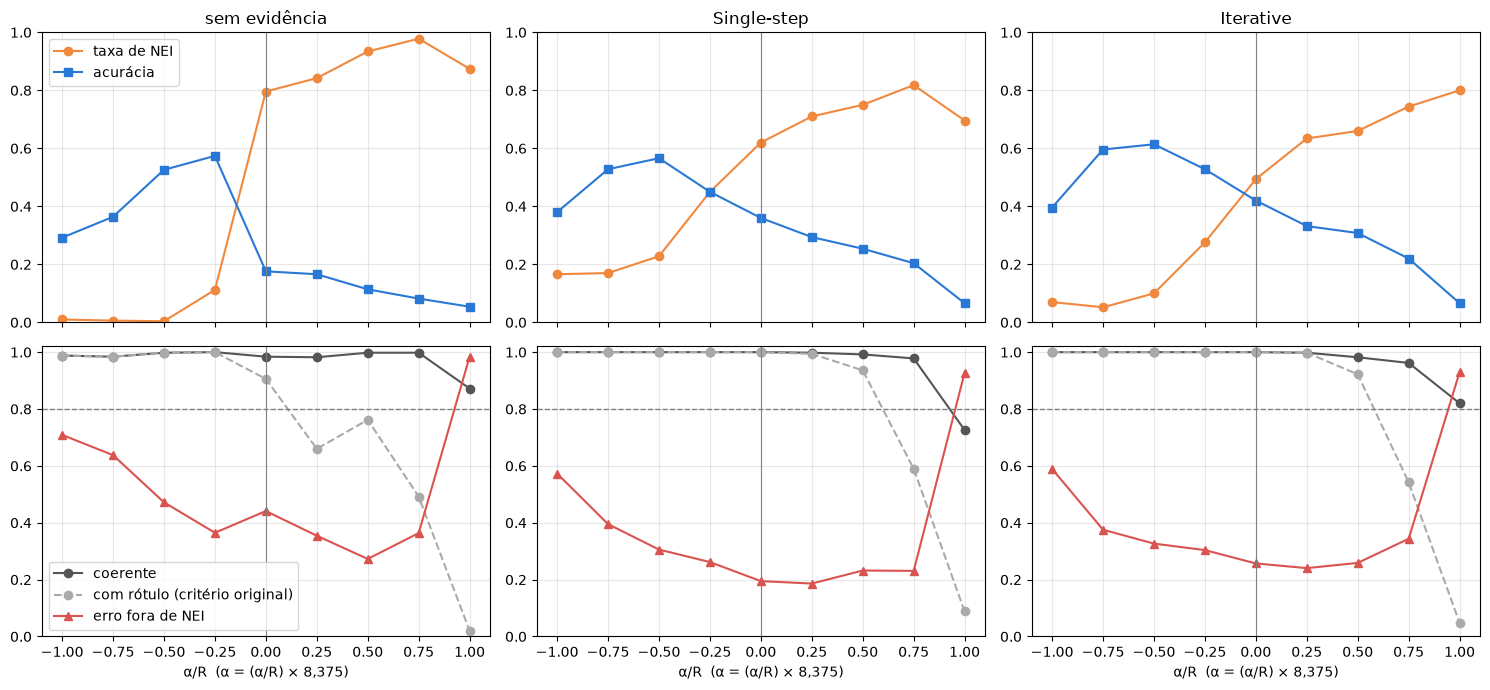

In [7]:
feat = [r for r in cells if r["direction"] in ("none",) or r["direction"].startswith("feat")]
feat = [r for r in feat if not r["subset"]]
if not feat:
    print("ainda sem células")
else:
    fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
    for j, cond in enumerate(COND):
        rs = sorted([r for r in feat if r["cond"] == cond], key=lambda r: r["beta"])
        if not rs: axes[0, j].set_title(f"{COND[cond]} (sem dados ainda)"); continue
        B = [r["beta"] for r in rs]; M = [metrics(r["pred"], r["gold"], r["readable"]) for r in rs]
        a = axes[0, j]; a.plot(B, [m["nei_rate"] for m in M], "o-", color="#f0883e", label="taxa de NEI")
        a.plot(B, [m["acc"] for m in M], "s-", color="#2a78d6", label="acurácia"); a.axvline(0, color="gray", lw=.8)
        a.set_ylim(0, 1); a.set_title(COND[cond]); a.grid(alpha=.3)
        b = axes[1, j]; b.plot(B, [m["legivel"] for m in M], "o-", color="#555", label="coerente")
        b.plot(B, [np.mean(r["label_ok"]) for r in rs], "o--", color="#aaa", label="com rótulo (critério original)")
        b.plot(B, [m["err_nonNEI"] for m in M], "^-", color="#d9534f", label="erro fora de NEI")
        b.axhline(THR, color="gray", ls="--", lw=1); b.axvline(0, color="gray", lw=.8); b.set_ylim(0, 1.02); b.grid(alpha=.3)
        b.set_xlabel("α/R  (α = (α/R) × 8,375)")
    axes[0, 0].legend(); axes[1, 0].legend(); plt.tight_layout(); plt.show()

### 5.2 Tabela completa por célula (500 claims)

**Como ler.** Uma linha por condição × α; colunas no formato do SA (Tabela 1) + taxa de NEI,
erro fora de NEI, coerência (critério principal) e "com rótulo" (critério original).

In [8]:
rows = []
for r in sorted(feat, key=lambda r: (list(COND).index(r["cond"]), r["beta"])):
    m = metrics(r["pred"], r["gold"], r["readable"]); mp = metrics(r["pred_pipeline"], r["gold"], r["readable"])
    rows.append([COND[r["cond"]], r["beta"], m["acc"], m["macroF1"], m["F1_SUP"], m["F1_REF"], m["F1_NEI"], m["F1_CONF"],
                 m["nei_rate"], m["err_nonNEI"], m["legivel"], np.mean(r["label_ok"]), mp["acc"], mp["nei_rate"]])
pd.DataFrame(rows, columns=["condição", "α/R", "Acc", "F1", "F1 SUP", "F1 REF", "F1 NEI", "F1 CONF", "NEI", "erro não-NEI", "coerente", "com rótulo", "Acc (regra pipeline)", "NEI (regra pipeline)"]) \
  .set_index(["condição", "α/R"]).round(3) if rows else "ainda sem células"


Acc     F1  F1 SUP  F1 REF  F1 NEI  F1 CONF    NEI  \
condição      α/R                                                           
sem evidência -1.00  0.292  0.224   0.411   0.160   0.100    0.000  0.010   
              -0.75  0.364  0.295   0.433   0.346   0.105    0.073  0.006   
              -0.50  0.526  0.365   0.450   0.645   0.000    0.000  0.004   
              -0.25  0.574  0.379   0.294   0.733   0.110    0.000  0.112   
               0.00  0.176  0.205   0.289   0.183   0.143    0.047  0.796   
               0.25  0.166  0.165   0.119   0.234   0.140    0.000  0.842   
               0.50  0.114  0.091   0.000   0.143   0.131    0.000  0.934   
               0.75  0.082  0.058   0.000   0.044   0.130    0.000  0.978   
               1.00  0.054  0.039   0.000   0.007   0.110    0.000  0.874   
Single-step   -1.00  0.380  0.352   0.437   0.415   0.203    0.000  0.166   
              -0.75  0.528  0.457   0.503   0.652   0.217    0.080  0.170   
              -0.50  0.566  0.486   0.554   0.702   0.201    0.047  0.228   
              -0.25  0.450  0.430   0.518   0.602   0.169    0.000  0.450   
               0.00  0.360  0.379   0.480   0.502   0.157    0.000  0.620   
               0.25  0.294  0.301   0.303   0.452   0.149    0.000  0.710   
               0.50  0.254  0.241   0.163   0.409   0.151    0.000  0.750   
               0.75  0.204  0.181   0.046   0.353   0.144    0.000  0.818   
               1.00  0.066  0.061   0.000   0.069   0.115    0.000  0.696   
Iterative     -1.00  0.396  0.352   0.444   0.412   0.200    0.000  0.070   
              -0.75  0.596  0.447   0.558   0.716   0.066    0.000  0.052   
              -0.50  0.614  0.465   0.557   0.744   0.094    0.000  0.100   
              -0.25  0.528  0.444   0.507   0.687   0.139    0.000  0.276   
               0.00  0.420  0.394   0.430   0.594   0.156    0.000  0.494   
               0.25  0.332  0.305   0.238   0.524   0.153    0.000  0.634   
               0.50  0.308  0.269   0.146   0.509   0.153    0.000  0.660   
               0.75  0.220  0.178   0.000   0.406   0.128    0.000  0.744   
               1.00  0.066  0.055   0.000   0.044   0.120    0.000  0.800   

                     erro não-NEI  coerente  com rótulo  Acc (regra pipeline)  \
condição      α/R                                                               
sem evidência -1.00         0.709     0.988       0.988                 0.316   
              -0.75         0.638     0.984       0.984                 0.384   
              -0.50         0.472     0.998       0.998                 0.534   
              -0.25         0.365     1.000       1.000                 0.620   
               0.00         0.441     0.984       0.906                 0.474   
               0.25         0.354     0.982       0.660                 0.346   
               0.50         0.273     0.998       0.762                 0.352   
               0.75         0.364     0.998       0.492                 0.202   
               1.00         0.984     0.872       0.020                 0.134   
Single-step   -1.00         0.573     1.000       1.000                 0.426   
              -0.75         0.395     1.000       1.000                 0.556   
              -0.50         0.306     1.000       1.000                 0.570   
              -0.25         0.262     1.000       1.000                 0.472   
               0.00         0.195     1.000       1.000                 0.434   
               0.25         0.186     0.998       0.994                 0.408   
               0.50         0.232     0.992       0.936                 0.402   
               0.75         0.231     0.978       0.590                 0.360   
               1.00         0.928     0.726       0.088                 0.134   
Iterative     -1.00         0.589     1.000       1.000                 0.426   
              -0.75         0.376     1.000       1.000                 0.606   
       

### 5.2.1 Matrizes de confusão de cada dose (500 claims)

**Como ler.** Uma figura por condição de evidência (sem evidência, Single-step, Iterative) e, dentro dela,
uma matriz por dose, lidas da esquerda para a direita e de cima para baixo: de α/R = −1 (feature mais
diminuída) a α/R = +1 (mais aumentada); a matriz do **centro**, **α/R = 0** (título em negrito), é o modelo
sem steering. Em cada matriz: **linhas = rótulo verdadeiro** (gold), **colunas =
rótulo que o modelo escreveu** (1º rótulo, §3.1), e cada célula é o **número de claims** (500 no total; as
linhas somam o gold: SUP 122, REF 305, NEI 35, CONF 38). A **diagonal** é o acerto; a **coluna NEI** mostra
quantos claims de cada classe viraram abstenção. A cor é relativa ao maior valor de cada matriz. No título:
α/R, α, acurácia e fração de respostas **em loop** (chegaram ao limite de 1.536 tokens, §2.3.2).

A grade executada vai de −1 a +1 em passos de 0,25 (os valores |α/R| > 1 da grade planejada foram cortados,
§2.3).

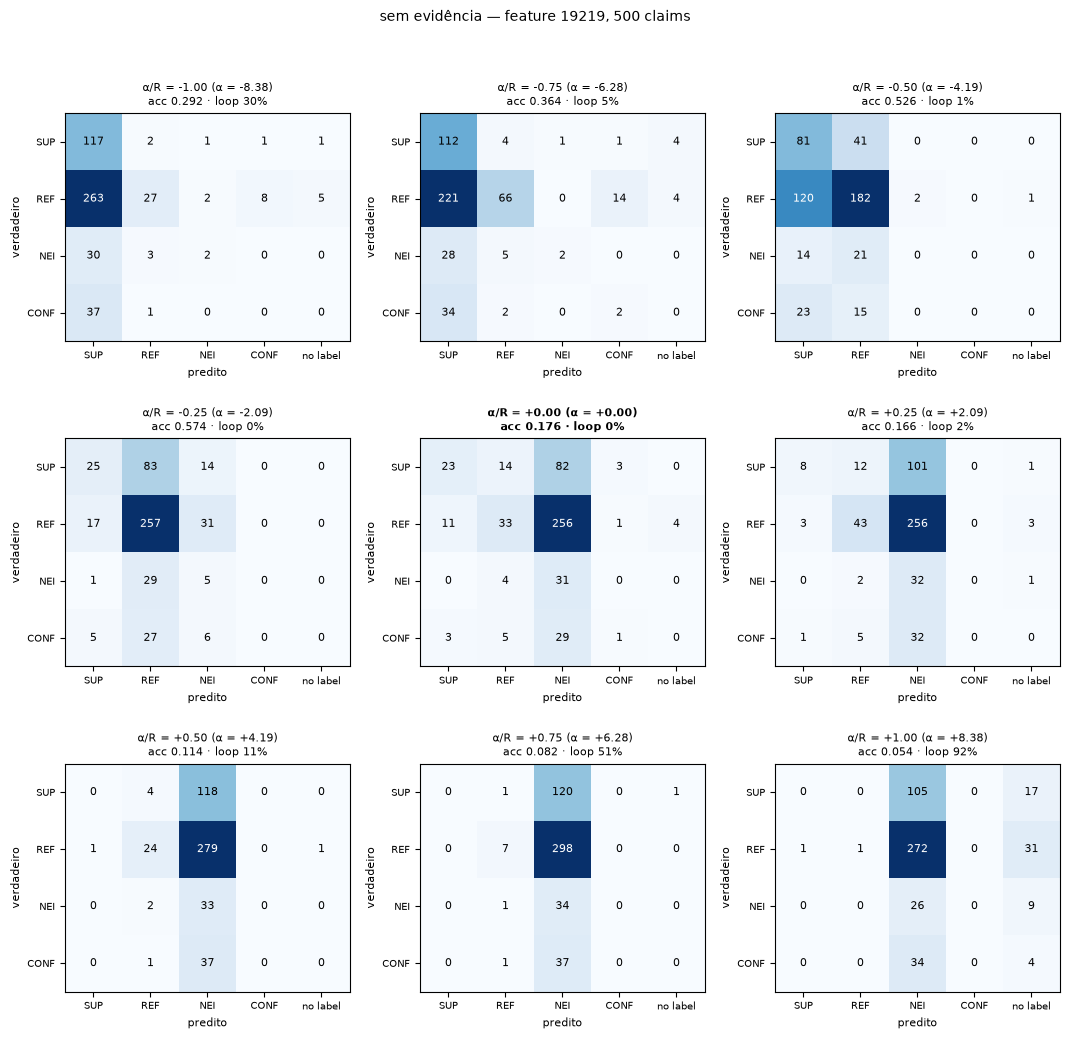

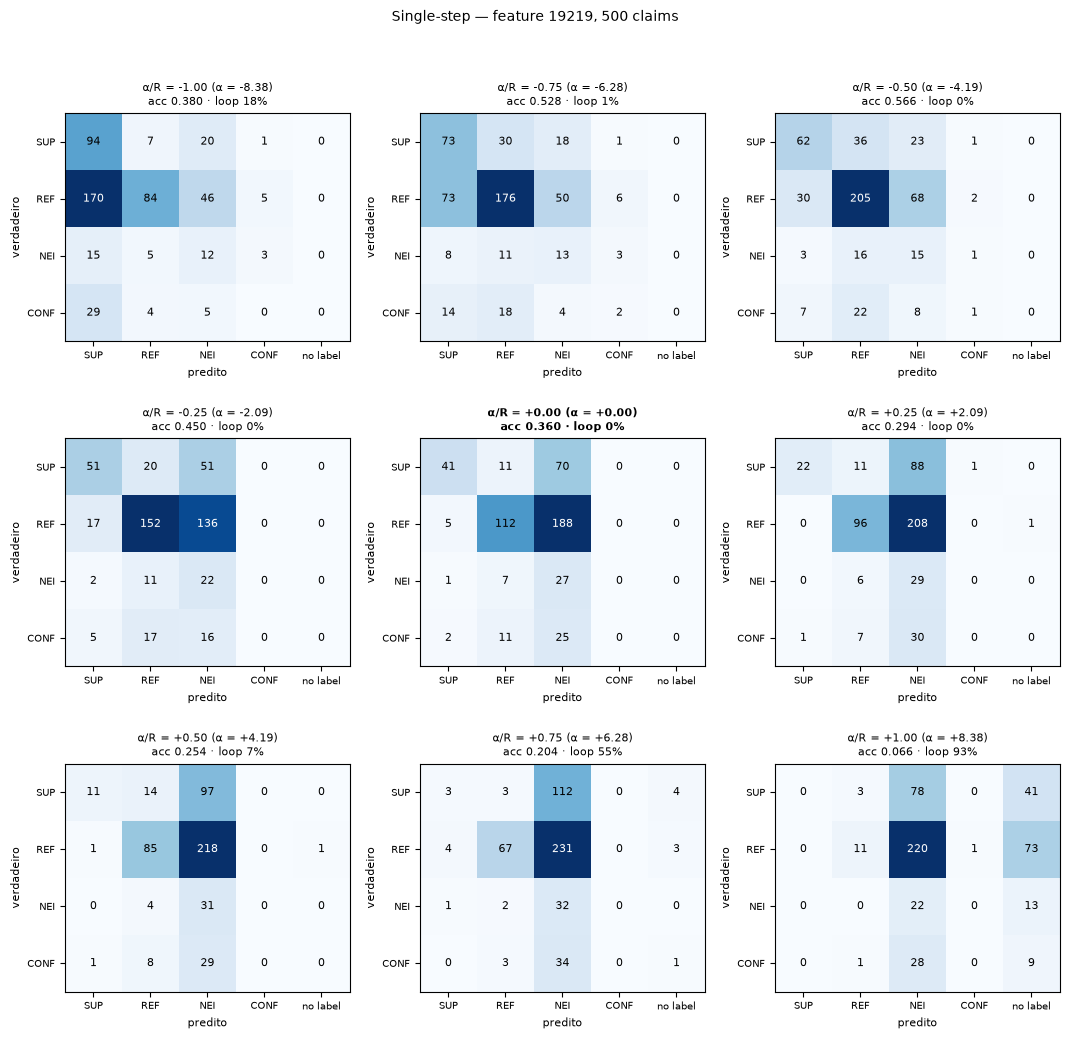

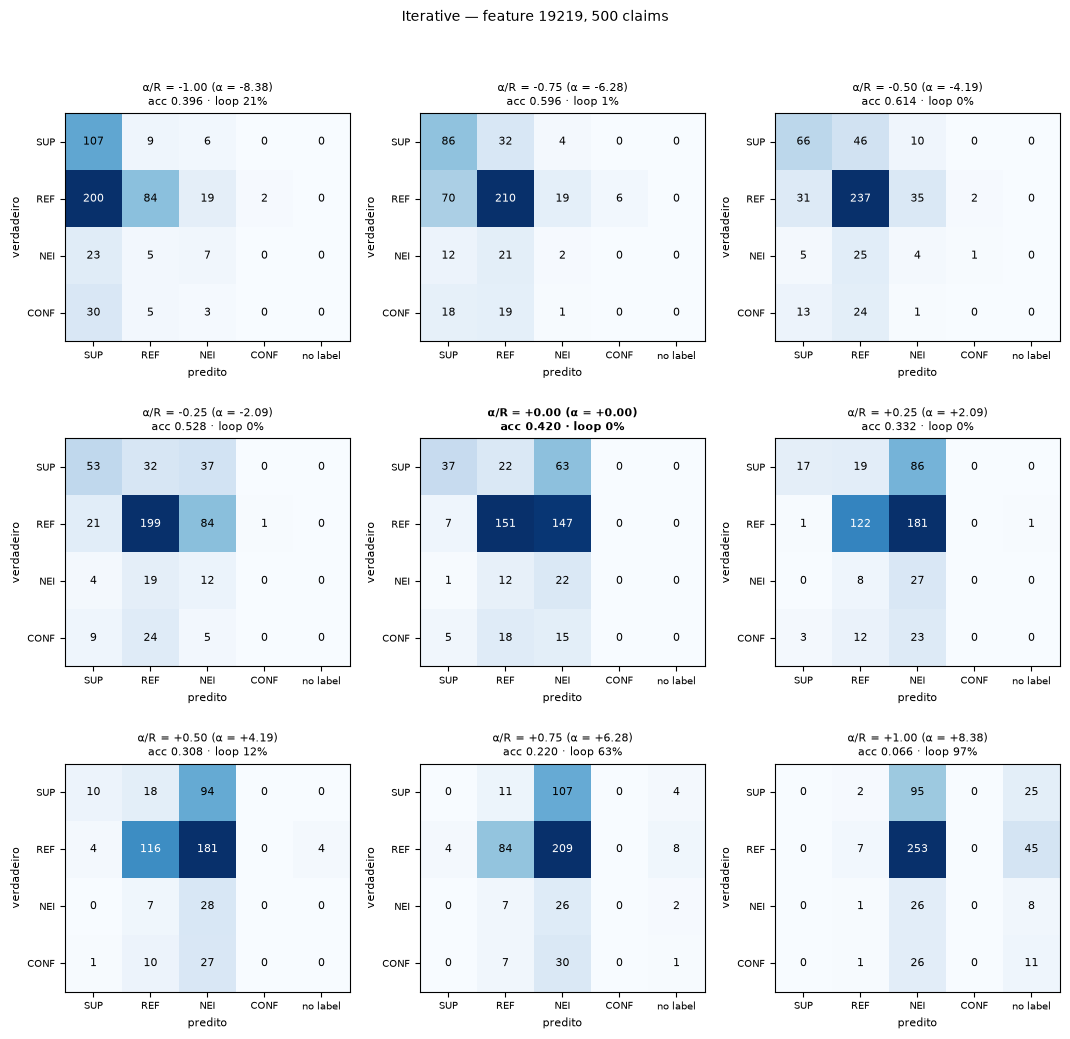

**Tabela das 27 matrizes** — cada coluna `X→Y` = claims com gold X que o modelo rotulou Y.

SUP→SUP  SUP→REF  SUP→NEI  SUP→CONF  SUP→NOLABEL  \
condição      α/R                                                       
sem evidência -1.00      117        2        1         1            1   
              -0.75      112        4        1         1            4   
              -0.50       81       41        0         0            0   
              -0.25       25       83       14         0            0   
               0.00       23       14       82         3            0   
               0.25        8       12      101         0            1   
               0.50        0        4      118         0            0   
               0.75        0        1      120         0            1   
               1.00        0        0      105         0           17   
Single-step   -1.00       94        7       20         1            0   
              -0.75       73       30       18         1            0   
              -0.50       62       36       23         1            0   
              -0.25       51       20       51         0            0   
               0.00       41       11       70         0            0   
               0.25       22       11       88         1            0   
               0.50       11       14       97         0            0   
               0.75        3        3      112         0            4   
               1.00        0        3       78         0           41   
Iterative     -1.00      107        9        6         0            0   
              -0.75       86       32        4         0            0   
              -0.50       66       46       10         0            0   
              -0.25       53       32       37         0            0   
               0.00       37       22       63         0            0   
               0.25       17       19       86         0            0   
               0.50       10       18       94         0            0   
               0.75        0       11      107         0            4   
               1.00        0        2       95         0           25   

                     REF→SUP  REF→REF  REF→NEI  REF→CONF  REF→NOLABEL  \
condição      α/R                                                       
sem evidência -1.00      263       27        2         8            5   
              -0.75      221       66        0        14            4   
              -0.50      120      182        2         0            1   
              -0.25       17      257       31         0            0   
               0.00       11       33      256         1            4   
               0.25        3       43      256         0            3   
               0.50        1       24      279         0            1   
               0.75        0        7      298         0            0   
               1.00        1        1      272         0           31   
Single-step   -1.00      170       84       46         5            0   
              -0.75       73      176       50         6            0   
              -0.50       30      205       68         2            0   
              -0.25       17      152      136         0            0   
               0.00        5      112      188         0            0   
               0.25        0       96      208         0            1   
               0.50        1       85      218         0            1   
               0.75        4       67      231         0            3   
               1.00        0       11      220         1           73   
Iterative     -1.00      200       84       19         2            0   
              -0.75       70      210       19         6            0   
              -0.50       31      237       35         2            0   
              -0.25       21      199       84         1            0   
               0.00        7      151      147         0            0   
               0.25        1      122      181         0            1   
     

In [9]:
PRED = CLS + ["NOLABEL"]                      # regra v2: coluna extra para resposta sem veredito (§3.1.2)
def cm4(pred, gold):
    M = np.zeros((4, 5), dtype=int)
    for p, g in zip(pred, gold):
        M[CLS.index(g), PRED.index(p)] += 1
    return M

for cond in COND:
    rs = sorted([r for r in cells500 if r["cond"] == cond], key=lambda r: r["beta"])
    if not rs: continue
    nc = 3; nr = int(np.ceil(len(rs) / nc))            # 3×3: α/R = 0 fica no centro
    fig, axes = plt.subplots(nr, nc, figsize=(3.6 * nc, 3.4 * nr))
    for ax in np.ravel(axes)[len(rs):]: ax.axis("off")
    for ax, r in zip(np.ravel(axes), rs):
        M = cm4(r["pred"], r["gold"]); acc = np.trace(M) / M.sum(); loop = np.mean(r["capped"])
        ax.imshow(M, cmap="Blues", vmin=0, vmax=M.max())
        for a in range(4):
            for b in range(5):
                ax.text(b, a, str(M[a, b]), ha="center", va="center", fontsize=8,
                        color="white" if M[a, b] > .6 * M.max() else "black")
        ax.set_xticks(range(5)); ax.set_xticklabels(["SUP", "REF", "NEI", "CONF", "no label"], fontsize=7)
        ax.set_yticks(range(4)); ax.set_yticklabels(CLS, fontsize=7)
        ax.set_title(f"α/R = {r['beta']:+.2f} (α = {r['beta'] * 8.375:+.2f})\nacc {acc:.3f} · loop {loop:.0%}", fontsize=8,
                     fontweight="bold" if r["beta"] == 0 else "normal")
        ax.set_ylabel("verdadeiro", fontsize=8)
        ax.set_xlabel("predito", fontsize=8)
    fig.suptitle(f"{COND[cond]} — feature 19219, 500 claims", fontsize=10, y=1.02)
    plt.tight_layout(); plt.show()

# as mesmas contagens em tabela (linhas = condição × α/R; colunas = verdadeiro→predito)
rows = []
for cond in COND:
    for r in sorted([r for r in cells500 if r["cond"] == cond], key=lambda r: r["beta"]):
        M = cm4(r["pred"], r["gold"])
        rows.append([COND[cond], r["beta"]] + [M[i, j] for i in range(4) for j in range(5)])
CM = pd.DataFrame(rows, columns=["condição", "α/R"] + [f"{g}→{p}" for g in CLS for p in PRED]).set_index(["condição", "α/R"])
display(Markdown("**Tabela das 27 matrizes** — cada coluna `X→Y` = claims com gold X que o modelo rotulou Y."))
CM

### 5.3 α escolhido na validação e resultado na metade de teste

**Como ler.** A 1ª tabela mostra, para **cada dose**, os números da **validação** (`claim_id` par) que as
regras da §2.3.2 usam — coerência, coerência sem loop e acurácia — e qual regra escolhe aquela dose.
A 2ª tabela, as métricas na metade de **teste** (`claim_id` ímpar) do α escolhido por cada regra,
contra o α = 0 na mesma metade.

In [10]:
def half(r, parity):
    idx = [i for i, cid in enumerate(r["ids"]) if cid % 2 == parity]
    return [r["pred"][i] for i in idx], [r["gold"][i] for i in idx], [r["readable"][i] for i in idx]

vrows = []
for cond in COND:
    picks = {(sign, rule): pick(cond, sign, rule) for sign in (-1, 1) for rule in RULES}
    for r in sorted([r for r in cells500 if r["cond"] == cond and r["beta"] != 0], key=lambda r: r["beta"]):
        v = val_stats(r); sign = int(np.sign(r["beta"]))
        vrows.append([COND[cond], r["beta"], v["coerente"], v["coerente_sem_loop"], v["acc"],
                      " ".join(rule for rule in RULES if picks[(sign, rule)] == r["beta"])])
display(Markdown("#### Validação: o que cada regra vê em cada dose"))
display(pd.DataFrame(vrows, columns=["condição", "α/R", "coerente", "coerente e sem loop", "acurácia", "escolhida pela regra"])
          .set_index(["condição", "α/R"]).round(3))

rows, chosen = [], {}
for cond in COND:
    rs = {r["beta"]: r for r in feat if r["cond"] == cond}
    if 0.0 not in rs: continue
    base = metrics(*half(rs[0.0], 1))
    rows.append([COND[cond], "baseline", "—", 0.0] + [base[k] for k in ("acc", "macroF1", "F1_NEI", "F1_CONF", "nei_rate", "err_nonNEI", "legivel")])
    for sense, sign in [("diminuir", -1), ("aumentar", 1)]:
        for rule in RULES:
            b = pick(cond, sign, rule)
            if b is None: continue
            chosen[(cond, sense, rule)] = b; m = metrics(*half(rs[b], 1))
            rows.append([COND[cond], sense, rule, b] + [m[k] for k in ("acc", "macroF1", "F1_NEI", "F1_CONF", "nei_rate", "err_nonNEI", "legivel")])
display(Markdown("#### Teste: métricas do α escolhido por cada regra"))
T = pd.DataFrame(rows, columns=["condição", "manipulação", "regra", "α/R", "Acc", "F1", "F1 NEI", "F1 CONF", "NEI", "erro não-NEI", "coerente"])
alt = {}
for cond in COND:
    rs = {r["beta"]: r for r in feat if r["cond"] == cond}
    for sense, sign in [("diminuir", -1), ("aumentar", 1)]:
        ok = [b for b, r in rs.items() if np.sign(b) == sign and
              np.mean([r["label_ok"][i] for i, cid in enumerate(r["ids"]) if cid % 2 == 0]) >= THR]
        if ok: alt[(cond, sense)] = max(ok, key=abs)
print("α/R que o critério original da §2.3 (COM RÓTULO, antes da §2.3.1) escolheria:", alt if alt else "—")
T.set_index(["condição", "manipulação", "regra"]).round(3) if rows else None

#### Validação: o que cada regra vê em cada dose

coerente  coerente e sem loop  acurácia  \
condição      α/R                                              
sem evidência -1.00     0.988                0.712     0.248   
              -0.75     0.976                0.944     0.316   
              -0.50     0.996                0.976     0.504   
              -0.25     1.000                1.000     0.584   
               0.25     0.980                0.960     0.152   
               0.50     1.000                0.900     0.120   
               0.75     1.000                0.476     0.092   
               1.00     0.872                0.052     0.056   
Single-step   -1.00     1.000                0.844     0.340   
              -0.75     1.000                0.988     0.516   
              -0.50     1.000                1.000     0.572   
              -0.25     1.000                1.000     0.460   
               0.25     1.000                1.000     0.276   
               0.50     0.996                0.944     0.256   
               0.75     0.976                0.508     0.196   
               1.00     0.732                0.056     0.076   
Iterative     -1.00     1.000                0.776     0.360   
              -0.75     1.000                0.988     0.592   
              -0.50     1.000                0.996     0.608   
              -0.25     1.000                1.000     0.536   
               0.25     1.000                1.000     0.348   
               0.50     0.988                0.884     0.312   
               0.75     0.980                0.368     0.224   
               1.00     0.844                0.028     0.072   

                    escolhida pela regra  
condição      α/R                         
sem evidência -1.00                    A  
              -0.75                    B  
              -0.50                       
              -0.25                    C  
               0.25                    C  
               0.50                    B  
               0.75                       
               1.00                    A  
Single-step   -1.00                  A B  
              -0.75                       
              -0.50                    C  
              -0.25                       
               0.25                    C  
               0.50                    B  
               0.75                    A  
               1.00                       
Iterative     -1.00                    A  
              -0.75                    B  
              -0.50                    C  
              -0.25                       
               0.25                    C  
               0.50                    B  
               0.75                       
               1.00                    A

#### Teste: métricas do α escolhido por cada regra

α/R que o critério original da §2.3 (COM RÓTULO, antes da §2.3.1) escolheria: {('none', 'diminuir'): -1.0, ('single', 'diminuir'): -1.0, ('single', 'aumentar'): 0.5, ('iterative', 'diminuir'): -1.0, ('iterative', 'aumentar'): 0.5}


α/R    Acc     F1  F1 NEI  F1 CONF    NEI  \
condição      manipulação regra                                               
sem evidência baseline    —      0.00  0.168  0.197   0.130    0.091  0.792   
              diminuir    A     -1.00  0.336  0.226   0.000    0.000  0.004   
                          B     -0.75  0.412  0.293   0.000    0.080  0.004   
                          C     -0.25  0.564  0.367   0.093    0.000  0.104   
              aumentar    A      1.00  0.052  0.039   0.103    0.000  0.868   
                          B      0.50  0.108  0.088   0.127    0.000  0.936   
                          C      0.25  0.180  0.181   0.136    0.000  0.816   
Single-step   baseline    —      0.00  0.364  0.370   0.154    0.000  0.608   
              diminuir    A     -1.00  0.420  0.398   0.286    0.000  0.156   
                          B     -1.00  0.420  0.398   0.286    0.000  0.156   
                          C     -0.50  0.560  0.482   0.225    0.000  0.216   
              aumentar    A      0.75  0.212  0.193   0.152    0.000  0.828   
                          B      0.50  0.252  0.235   0.148    0.000  0.744   
                          C      0.25  0.312  0.319   0.157    0.000  0.696   
Iterative     baseline    —      0.00  0.420  0.401   0.156    0.000  0.496   
              diminuir    A     -1.00  0.432  0.372   0.188    0.000  0.060   
                          B     -0.75  0.600  0.453   0.071    0.000  0.044   
                          C     -0.50  0.620  0.485   0.140    0.000  0.104   
              aumentar    A      1.00  0.060  0.052   0.105    0.000  0.772   
                          B      0.50  0.304  0.279   0.154    0.000  0.660   
                          C      0.25  0.316  0.304   0.146    0.000  0.644   

                                 erro não-NEI  coerente  
condição      manipulação regra                          
sem evidência baseline    —             0.462     0.984  
              diminuir    A             0.663     0.988  
                          B             0.586     0.992  
                          C             0.379     1.000  
              aumentar    A             0.970     0.872  
                          B             0.312     0.996  
                          C             0.348     0.984  
Single-step   baseline    —             0.204     1.000  
              diminuir    A             0.540     1.000  
                          B             0.540     1.000  
                          C             0.327     1.000  
              aumentar    A             0.163     0.980  
                          B             0.250     0.988  
                          C             0.171     0.996  
Iterative     baseline    —             0.254     1.000  
              diminuir    A             0.553     1.000  
                          B             0.377     1.000  
                          C             0.321     1.000  
              aumentar    A             0.930     0.796  
                          B             0.271     0.976  
                          C             0.258     0.996

### 5.4 Controle: feature 19219 × 10 features aleatórias (100 claims de teste)

**Como ler.** Para cada condição e α escolhido: a taxa de NEI e a acurácia com a feature 19219
e a média (± desvio) com as 10 features aleatórias, nos mesmos 100 claims. Se a feature é
específica, as aleatórias devem ficar perto do α = 0.

In [11]:
rand = [r for r in cells if r["direction"].startswith("rand") and r["subset"]]
if not rand:
    print("controle aleatório adiado (decisão do Lucas, 29/09/2026 — ver §2.4)")
else:
    rows = []
    for cond in COND:
        for b in sorted({r["beta"] for r in rand if r["cond"] == cond}):
            R_ = [r for r in rand if r["cond"] == cond and r["beta"] == b]; ids = set(R_[0]["ids"])
            fr = next((r for r in feat if r["cond"] == cond and r["beta"] == b), None)
            b0 = next((r for r in feat if r["cond"] == cond and r["beta"] == 0.0), None)
            sub = lambda r: ([p for i, p in zip(r["ids"], r["pred"]) if i in ids], [g for i, g in zip(r["ids"], r["gold"]) if i in ids])
            nei = [np.mean([p == "NEI" for p in r["pred"]]) for r in R_]; acc = [np.mean([p == g for p, g in zip(r["pred"], r["gold"])]) for r in R_]
            fp, fg = sub(fr) if fr else ([], []); bp, bg = sub(b0) if b0 else ([], [])
            rows.append([COND[cond], b, len(R_), np.mean([p == "NEI" for p in bp]) if bp else np.nan,
                         np.mean([p == "NEI" for p in fp]) if fp else np.nan, f"{np.mean(nei):.3f} ± {np.std(nei):.3f}",
                         np.mean([p == g for p, g in zip(fp, fg)]) if fp else np.nan, f"{np.mean(acc):.3f} ± {np.std(acc):.3f}"])
    display(pd.DataFrame(rows, columns=["condição", "α/R", "nº aleatórias", "NEI α=0", "NEI feature 19219", "NEI aleatórias",
                                        "acc feature 19219", "acc aleatórias"]).round(3))

controle aleatório adiado (decisão do Lucas, 29/09/2026 — ver §2.4)


### 5.4 Gemma-3-4B, feature 12903 (18/10/2026)

Mesmo protocolo (500 claims; 3 condições), com duas diferenças: a dose é medida em $\alpha/R_c$ (norma centrada,
$R_c = 839$; decisão de 12/10/2026, porque a dimensão 443 do Gemma3 vale ~32.768 em todo token e infla a norma média)
e a grade vai de −6 a +6 (equivalente, em força relativa, a ±1 na régua antiga do Llama). Rótulo: regra v2 (§3.1.2).

In [12]:
import glob, collections
from fcsae.steering.factcheck_sae import verdict_label
G = "../results/v3_gemma3/steer_sae"
rows = []
for cond in ["none", "single", "iterative"]:
    for f in glob.glob(f"{G}/{cond}__*__b*.json"):
        if "__all" in f or "__test" in f: continue
        r = json.load(open(f, encoding="utf-8"))
        if len(r["ids"]) < 500: continue
        p = [verdict_label(x) for x in r["raw"]]; c = collections.Counter(p); n = len(p)
        rows.append([COND[cond], r["beta"], np.mean([a == g for a, g in zip(p, r["gold"])]),
                     c["SUP"] / n, c["REF"] / n, c["NEI"] / n, c["CONF"] / n, c["NOLABEL"] / n])
G3 = pd.DataFrame(rows, columns=["condição", "α/R_c", "Acc", "SUP", "REF", "NEI", "CONF", "sem rótulo"])
G3.sort_values(["condição", "α/R_c"]).set_index(["condição", "α/R_c"]).round(3)

Acc    SUP    REF    NEI   CONF  sem rótulo
condição      α/R_c                                               
Iterative     -6.0   0.000  0.000  0.004  0.002  0.002       0.992
              -4.5   0.290  0.076  0.386  0.040  0.068       0.430
              -3.0   0.642  0.116  0.860  0.016  0.002       0.006
              -1.5   0.628  0.030  0.964  0.006  0.000       0.000
               0.0   0.624  0.024  0.968  0.008  0.000       0.000
               1.5   0.602  0.004  0.964  0.030  0.002       0.000
               3.0   0.478  0.012  0.680  0.256  0.016       0.036
               4.5   0.254  0.002  0.304  0.662  0.000       0.032
               6.0   0.128  0.000  0.136  0.442  0.000       0.422
Single-step   -6.0   0.000  0.002  0.002  0.000  0.000       0.996
              -4.5   0.326  0.130  0.392  0.084  0.046       0.348
              -3.0   0.606  0.120  0.818  0.058  0.002       0.002
              -1.5   0.608  0.052  0.908  0.040  0.000       0.000
               0.0   0.590  0.030  0.908  0.062  0.000       0.000
               1.5   0.530  0.010  0.836  0.152  0.002       0.000
               3.0   0.466  0.012  0.658  0.320  0.002       0.008
               4.5   0.272  0.000  0.360  0.598  0.004       0.038
               6.0   0.136  0.000  0.154  0.412  0.000       0.434
sem evidência -6.0   0.004  0.010  0.000  0.000  0.002       0.988
              -4.5   0.444  0.574  0.292  0.008  0.098       0.028
              -3.0   0.642  0.220  0.764  0.016  0.000       0.000
              -1.5   0.592  0.022  0.902  0.076  0.000       0.000
               0.0   0.306  0.008  0.364  0.480  0.148       0.000
               1.5   0.104  0.000  0.040  0.960  0.000       0.000
               3.0   0.056  0.024  0.008  0.714  0.000       0.254
               4.5   0.170  0.000  0.202  0.476  0.004       0.318
               6.0   0.000  0.000  0.000  0.006  0.000       0.994

👉 **Leitura.** A 12903 **controla a abstenção nos dois sentidos**: aumentá-la sobe o NEI nas três condições
(sem evidência 48% → 96% em +1,5; Single 6% → 60% em +4,5; Iterative 1% → 66% em +4,5); diminuí-la tira a abstenção —
sem evidência a acurácia **dobra** (0,306 → 0,642 em −3); com evidência o ganho é pequeno (Single 0,590 → 0,608;
Iterative 0,624 → 0,642), pois o modelo quase não abstém. Faixa útil: −3 a +4,5; em ±6 o texto degenera (~99% sem
rótulo). Contraste: no Qwen3 a 12482 codifica "não sustentado" (alta em REF e NEI) e só empurra SUP ↔ REF (FAQ 33).

### 5.5 Qwen3-8B, feature 12482

Mesmo protocolo e mesma grade do Llama (rodada na régua antiga, $\alpha/R$ de −1 a +1 com a norma média
$R = 131{,}81$); a tabela mostra também a dose convertida para a régua comum, $\alpha/R_c$ ($R_c = 22{,}70$; ×5,81).
Rótulo: regra v2 (§3.1.2).

In [13]:
Q = "../results/v3_qwen3_l22/steer_sae"
qn = json.load(open("/mnt/d/Projetos WSL/fcsae-store/results/v3_qwen3_l22/residual_norm_decision.json"))
conv = qn["R"] / qn["R_centered"]
rows = []
for cond in ["none", "single", "iterative"]:
    for f in glob.glob(f"{Q}/{cond}__*__b*.json"):
        if "__all" in f or "__test" in f: continue
        r = json.load(open(f, encoding="utf-8"))
        if len(r["ids"]) < 500: continue
        p = [verdict_label(x) for x in r["raw"]]; c = collections.Counter(p); n = len(p)
        rows.append([COND[cond], r["beta"], round(r["beta"] * conv, 2), np.mean([a == g for a, g in zip(p, r["gold"])]),
                     c["SUP"] / n, c["REF"] / n, c["NEI"] / n, c["CONF"] / n, c["NOLABEL"] / n])
Q3 = pd.DataFrame(rows, columns=["condição", "α/R (régua antiga)", "α/R_c", "Acc", "SUP", "REF", "NEI", "CONF", "sem rótulo"])
Q3.sort_values(["condição", "α/R_c"]).set_index(["condição", "α/R_c"]).round(3)

α/R (régua antiga)    Acc    SUP    REF    NEI  CONF  \
condição      α/R_c                                                         
Iterative     -5.81               -1.00  0.240  0.982  0.000  0.000   0.0   
              -4.35               -0.75  0.244  1.000  0.000  0.000   0.0   
              -2.90               -0.50  0.300  0.934  0.066  0.000   0.0   
              -1.45               -0.25  0.334  0.890  0.108  0.002   0.0   
               0.00                0.00  0.452  0.216  0.368  0.416   0.0   
               1.45                0.25  0.366  0.000  0.580  0.420   0.0   
               2.90                0.50  0.398  0.000  0.624  0.376   0.0   
               4.35                0.75  0.388  0.000  0.612  0.384   0.0   
               5.81                1.00  0.370  0.000  0.582  0.400   0.0   
Single-step   -5.81               -1.00  0.242  0.992  0.000  0.000   0.0   
              -4.35               -0.75  0.244  1.000  0.000  0.000   0.0   
              -2.90               -0.50  0.272  0.962  0.038  0.000   0.0   
              -1.45               -0.25  0.288  0.938  0.060  0.002   0.0   
               0.00                0.00  0.400  0.126  0.304  0.570   0.0   
               1.45                0.25  0.310  0.000  0.426  0.574   0.0   
               2.90                0.50  0.362  0.000  0.494  0.506   0.0   
               4.35                0.75  0.352  0.000  0.488  0.510   0.0   
               5.81                1.00  0.342  0.000  0.466  0.512   0.0   
sem evidência -5.81               -1.00  0.244  1.000  0.000  0.000   0.0   
              -4.35               -0.75  0.244  1.000  0.000  0.000   0.0   
              -2.90               -0.50  0.244  1.000  0.000  0.000   0.0   
              -1.45               -0.25  0.244  1.000  0.000  0.000   0.0   
               0.00                0.00  0.450  0.000  0.704  0.296   0.0   
               1.45                0.25  0.524  0.000  0.836  0.164   0.0   
               2.90                0.50  0.556  0.000  0.890  0.110   0.0   
               4.35                0.75  0.516  0.000  0.808  0.192   0.0   
               5.81                1.00  0.366  0.000  0.436  0.546   0.0   

                     sem rótulo  
condição      α/R_c              
Iterative     -5.81       0.018  
              -4.35       0.000  
              -2.90       0.000  
              -1.45       0.000  
               0.00       0.000  
               1.45       0.000  
               2.90       0.000  
               4.35       0.004  
               5.81       0.018  
Single-step   -5.81       0.008  
              -4.35       0.000  
              -2.90       0.000  
              -1.45       0.000  
               0.00       0.000  
               1.45       0.000  
               2.90       0.000  
               4.35       0.002  
               5.81       0.022  
sem evidência -5.81       0.000  
              -4.35       0.000  
              -2.90       0.000  
              -1.45       0.000  
               0.00       0.000  
               1.45       0.000  
               2.90       0.000  
               4.35       0.000  
               5.81       0.018

👉 **Leitura.** A 12482 **não controla a abstenção**: ela controla o eixo **"a evidência sustenta / não sustenta"**.
**Diminuí-la** leva o modelo a responder **SUPPORTED a quase tudo** nas três condições (sem evidência, 100% SUP já em
α/R_c = −2,90; o modelo chega a escrever *"the task assumes that the evidence is sufficient to support the claim"*);
**aumentá-la** elimina o SUP e quem cresce é o **REF** — o NEI **não sobe** com evidência (Single 57,0% → 50,6%;
Iterative 41,6% → 37,6% em +2,90) e sem evidência até cai (29,6% → 11,0%). Nenhuma dose melhora a acurácia com
evidência.

**Por quê:** a ativação média da 12482 nos dados de treino é quase igual em REF (0,161) e NEI (0,174), contra 0,067 em
SUP — ela codifica "não sustentado", não "evidência insuficiente". O critério de seleção (NEI × SUP+REF juntos) não
distingue as duas coisas, porque SUP é o grupo maior (FAQ 33). Contraste: a 19219 (Llama) e a 12903 (Gemma3, §5.4) são
específicas de NEI e controlam a abstenção nos dois sentidos. É um exemplo de que **detectar ≠ controlar**
(Arad et al., 2025). Decisão do Lucas (14/10/2026): manter a 12482 (sem refazer a triagem).

## 6. Limitações previstas

1. **Um modelo só (Llama).** DeepSeek e Qwen3 entram quando os SAEs v3 deles estiverem prontos.
2. **Baseline num ambiente diferente do pipeline original** — mitigado usando o nosso α = 0
   como referência e reportando a concordância (§4.1).
3. **A regra de rótulo do pipeline** transforma respostas sem rótulo em NEI e pega "FALSE" em
   qualquer ponto do texto como REF. Mantemos a regra por fidelidade, e reportamos a
   coerência e "com rótulo" à parte.
4. **Limiar de coerência (80%)** e a **lista de frases de recusa** são escolhas nossas (a lista foi definida depois das 2 primeiras células sem evidência e congelada — §2.3.1); a curva completa e o critério original mostram a sensibilidade.
5. **Controle aleatório em 100 claims**, como em Ferrando et al. (2025), não nos 500.


## Referências

- **Arditi, A., et al. (2024).** Refusal in Language Models Is Mediated by a Single Direction. *NeurIPS 2024. arXiv:2406.11717.*
- **Ferrando, J., Obeso, O., Rajamanoharan, S., & Nanda, N. (2025).** Do I Know This Entity? Knowledge Awareness and Hallucinations in Language Models. *ICLR 2025. arXiv:2411.14257.*
- **O'Brien, K., et al. (2024).** Steering Language Model Refusal with Sparse Autoencoders. *arXiv:2411.11296.*
- **Panickssery, N., et al. (2024).** Steering Llama 2 via Contrastive Activation Addition. *arXiv:2312.06681.*
- **Tan, D., et al. (2024).** Analysing the Generalisation and Reliability of Steering Vectors. *arXiv:2407.12404.*
- **Turner, A. M., et al. (2023).** Steering Language Models With Activation Engineering. *arXiv:2308.10248.*
- **Dietterich, T. G. (1998).** Approximate Statistical Tests for Comparing Supervised Classification Learning Algorithms. *Neural Computation, 10*(7), 1895–1923.
- **McNemar, Q. (1947).** Note on the Sampling Error of the Difference Between Correlated Proportions or Percentages. *Psychometrika, 12*(2), 153–157.
- **Fraga, L. M., & Kupssinskü, L. S. (2026).** Less is More: Improved Fact-Checking on AVeriTeC with Iterative Question Generation. *ENIAC 2026* (Seminário de Andamento, PPGCC/PUCRS).
